In [1]:
import os

# Same thread settings as the reference notebook.
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import gc, json, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Same seed as the reference notebook (RANDOM_STATE = 42). Used for the Random Forest and
# for every random choice in this notebook (permutation importance, land-cover site selection).
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.0 | pandas 3.0.5 | numpy 2.5.4


In [2]:
# Configuration
DATA_PATH = "MainData.csv"                 # same file the reference notebook loads
OUTPUT_DIR = "counterfactual_outputs"      # tables / figures / preprocessing parameters are saved here
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET = "pm25"
TIME_COL = "datetime"
ID_COL = "sensor_id"

DUST_EVENT_START = "2022-03-20"            # inclusive (reference)
DUST_EVENT_END = "2022-03-26"              # inclusive (reference)

DAY_OF_WEEK_ENCODING = "ordinal"           # 1 = Sunday ... 7 = Saturday (reference)
LOCATION_CLUSTER_THRESHOLD_M = 30.0        # reference haversine merge tolerance

LOOKBACK = 14                              # reference: best lookback for the Random Forest (Experiment 1)
WINSOR_PERCENTILE = 0.995                  # reference: final winsorization percentile

# Main design switch
INCLUDE_PM25_LAGS_AS_INPUT = True       # False = spec (no past PM2.5 in X). True = reference RF as actually built.

# Feature definitions: identical to the reference notebook
CONTINUOUS_FEATURES = [
    "road_length_250m", "major_road_length_250m", "nearest_traffic_aadf", "traffic_distance_m",
    "temperature", "humidity", "wind_speed", "solar_irradiance", "rainfall",
    "ndvi_v3_final", "dist_to_nearest_station_m",
]
BINARY_FEATURES = [
    "is_weekend", "is_public_holiday",
    "landcover_2020_group_Built-up",          # "Built-up"
    "landcover_2020_group_Green/open space",  # "Green-open"
    "landcover_2020_group_Tree cover",        # "Tree cover"
]
CATEGORICAL_FEATURES = ["day_of_week"]
ALL_BASE_FEATURES = CONTINUOUS_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES

# Verification targets quoted in the spec (not used anywhere in fitting; comparison printouts only).
REFERENCE_TARGETS = {
    "n_train": 1_580_213, "n_test": 395_052,
    "train_end": "2025-04-17 16:12:53", "test_start": "2025-04-17 16:13:03",
    "winsor_threshold": 56.06, "MAE": 2.015, "RMSE": 3.250, "R2": 0.829,
    "n_eligible_L14": 1_024_158,   # reference lookback coverage table, L = 14
}
print(f"Base features: {len(ALL_BASE_FEATURES)} | lookback L = {LOOKBACK} | "
      f"past PM2.5 as model input: {INCLUDE_PM25_LAGS_AS_INPUT}")

Base features: 17 | lookback L = 14 | past PM2.5 as model input: True


In [3]:
# Load once. df_original is never modified anywhere in this notebook.
# Only the columns this analysis needs are read (the file has 77 columns); nothing else is used downstream.
_header = pd.read_csv(DATA_PATH, nrows=0).columns
LAT_COL = next((c for c in ["latitude", "lat", "Latitude", "Lat"] if c in _header), None)
LON_COL = next((c for c in ["longitude", "lon", "long", "Longitude", "Lon"] if c in _header), None)
print(f"Detected LAT_COL = {LAT_COL!r}, LON_COL = {LON_COL!r}")

_needed = [TIME_COL, ID_COL, TARGET] + [c for c in [LAT_COL, LON_COL] if c] + \
          [c for c in ALL_BASE_FEATURES if c != "day_of_week"]
_missing = [c for c in _needed if c not in _header]
assert not _missing, f"Columns missing from {DATA_PATH}: {_missing}"

df_original = pd.read_csv(DATA_PATH, usecols=_needed)
df_original[TIME_COL] = pd.to_datetime(df_original[TIME_COL])

print("Shape (needed columns only):", df_original.shape)
print("Date range:", df_original[TIME_COL].min(), "to", df_original[TIME_COL].max())
df_original.head()

Detected LAT_COL = 'latitude', LON_COL = 'longitude'
Shape (needed columns only): (1977329, 21)
Date range: 2020-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00


,datetime,pm25,latitude,longitude,road_length_250m,major_road_length_250m,nearest_traffic_aadf,traffic_distance_m,is_weekend,is_public_holiday,...,temperature,humidity,wind_speed,solar_irradiance,rainfall,sensor_id,ndvi_v3_final,landcover_2020_group_Built-up,landcover_2020_group_Green/open space,landcover_2020_group_Tree cover
0,2020-01-01 00:00:00+00:00,21.0,51.45258,0.070766,1947.21024,1703.030117,84199.0,1184.35823,0,1,...,5.259911,94.187330,2.835601,0.0,0.030930,228,0.66,0,0,1
1,2020-01-01 01:00:00+00:00,23.0,51.45258,0.070766,1947.21024,1703.030117,84199.0,1184.35823,0,1,...,4.723274,94.663419,2.407921,0.0,0.000859,228,0.66,0,0,1
2,2020-01-01 02:00:00+00:00,24.0,51.45258,0.070766,1947.21024,1703.030117,84199.0,1184.35823,0,1,...,4.426212,95.051324,2.080389,0.0,0.004389,228,0.66,0,0,1
3,2020-01-01 03:00:00+00:00,25.0,51.45258,0.070766,1947.21024,1703.030117,84199.0,1184.35823,0,1,...,4.079609,96.000684,1.857610,0.0,0.004584,228,0.66,0,0,1
4,2020-01-01 04:00:00+00:00,26.0,51.45258,0.070766,1947.21024,1703.030117,84199.0,1184.35823,0,1,...,4.170018,95.924746,1.679910,0.0,0.003511,228,0.66,0,0,1


In [4]:
df_clean = df_original.copy()

col_tz = df_clean[TIME_COL].dt.tz
start_bound = pd.Timestamp(DUST_EVENT_START, tz=col_tz)
end_bound = pd.Timestamp(DUST_EVENT_END, tz=col_tz) + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)

dust_event_mask = (df_clean[TIME_COL] >= start_bound) & (df_clean[TIME_COL] <= end_bound)

n_original = len(df_original)
n_removed = int(dust_event_mask.sum())

df_clean = df_clean.loc[~dust_event_mask].reset_index(drop=True)

print(f"Observations before removal : {n_original:,}")
print(f"Observations removed        : {n_removed:,}  (Mar 20-26, 2022 dust event)")
print(f"Observations remaining      : {len(df_clean):,}")
print(f"Percentage removed          : {100 * n_removed / n_original:.4f}%")
if n_removed > 0:
    removed = df_original.loc[dust_event_mask]
    print(f"Removed range               : {removed[TIME_COL].min()} to {removed[TIME_COL].max()}")

assert ((df_clean[TIME_COL] >= start_bound) & (df_clean[TIME_COL] <= end_bound)).sum() == 0
assert len(df_original) == n_original
print("Verified: no dust-event rows remain in df_clean; df_original is unchanged.")

Observations before removal : 1,977,329
Observations removed        : 2,064  (Mar 20-26, 2022 dust event)
Observations remaining      : 1,975,265
Percentage removed          : 0.1044%
Removed range               : 2022-03-20 00:00:00+00:00 to 2022-03-26 23:00:00+00:00
Verified: no dust-event rows remain in df_clean; df_original is unchanged.


In [5]:
def add_ordinal_day_of_week(frame):
    frame = frame.copy()
    pandas_dow = frame[TIME_COL].dt.dayofweek          # Monday=0 ... Sunday=6
    frame["day_of_week"] = ((pandas_dow + 1) % 7) + 1  # Sunday=1 ... Saturday=7
    return frame

df_clean = add_ordinal_day_of_week(df_clean)

check = df_clean[[TIME_COL, "day_of_week"]].head(7).copy()
check["weekday_name"] = check[TIME_COL].dt.day_name()
assert (check.assign(exp=lambda d: d["weekday_name"].map(
    {"Sunday": 1, "Monday": 2, "Tuesday": 3, "Wednesday": 4, "Thursday": 5, "Friday": 6, "Saturday": 7}))
    ["exp"] == check["day_of_week"]).all()
check

,datetime,day_of_week,weekday_name
0,2020-01-01 00:00:00+00:00,4,Wednesday
1,2020-01-01 01:00:00+00:00,4,Wednesday
2,2020-01-01 02:00:00+00:00,4,Wednesday
3,2020-01-01 03:00:00+00:00,4,Wednesday
4,2020-01-01 04:00:00+00:00,4,Wednesday
5,2020-01-01 05:00:00+00:00,4,Wednesday
6,2020-01-01 06:00:00+00:00,4,Wednesday


In [6]:
df_clean = df_clean.sort_values(TIME_COL).reset_index(drop=True)

split_index = int(len(df_clean) * 0.80)
split_time_candidate = df_clean[TIME_COL].iloc[split_index]
while split_index < len(df_clean) and df_clean[TIME_COL].iloc[split_index] == split_time_candidate:
    split_index += 1

train_df = df_clean.iloc[:split_index].copy()
test_df = df_clean.iloc[split_index:].copy()

assert train_df[TIME_COL].max() < test_df[TIME_COL].min(), "Training data must fully precede testing data."
SPLIT_BOUNDARY_TIME = train_df[TIME_COL].max()

print(f"Training set : {len(train_df):>10,} rows | {train_df[TIME_COL].min()}  ->  {train_df[TIME_COL].max()}")
print(f"Testing set  : {len(test_df):>10,} rows | {test_df[TIME_COL].min()}  ->  {test_df[TIME_COL].max()}")
print(f"Fixed train/test boundary time: {SPLIT_BOUNDARY_TIME}")

print("\nComparison with the previously established split (verification only):")
print(f"  train rows  actual={len(train_df):,}  reference={REFERENCE_TARGETS['n_train']:,}  "
      f"-> {'match' if len(train_df) == REFERENCE_TARGETS['n_train'] else 'DIFFERENT (dataset may have changed)'}")
print(f"  test rows   actual={len(test_df):,}  reference={REFERENCE_TARGETS['n_test']:,}  "
      f"-> {'match' if len(test_df) == REFERENCE_TARGETS['n_test'] else 'DIFFERENT (dataset may have changed)'}")
print(f"  train end   actual={train_df[TIME_COL].max().strftime('%Y-%m-%d %H:%M:%S')}  "
      f"reference={REFERENCE_TARGETS['train_end']}")
print(f"  test start  actual={test_df[TIME_COL].min().strftime('%Y-%m-%d %H:%M:%S')}  "
      f"reference={REFERENCE_TARGETS['test_start']}")

Training set :  1,580,213 rows | 2020-01-01 00:00:00+00:00  ->  2025-04-17 16:12:53+00:00
Testing set  :    395,052 rows | 2025-04-17 16:13:03+00:00  ->  2025-12-31 23:00:00+00:00
Fixed train/test boundary time: 2025-04-17 16:12:53+00:00

Comparison with the previously established split (verification only):
  train rows  actual=1,580,213  reference=1,580,213  -> match
  test rows   actual=395,052  reference=395,052  -> match
  train end   actual=2025-04-17 16:12:53  reference=2025-04-17 16:12:53
  test start  actual=2025-04-17 16:13:03  reference=2025-04-17 16:13:03


In [7]:
CURRENT_FEATURE_COLS = CONTINUOUS_FEATURES + BINARY_FEATURES + ["day_of_week"]   # reference column order
assert sorted(CURRENT_FEATURE_COLS) == sorted(ALL_BASE_FEATURES)
print(f"{len(CURRENT_FEATURE_COLS)} current features:")
print(CURRENT_FEATURE_COLS)

17 current features:
['road_length_250m', 'major_road_length_250m', 'nearest_traffic_aadf', 'traffic_distance_m', 'temperature', 'humidity', 'wind_speed', 'solar_irradiance', 'rainfall', 'ndvi_v3_final', 'dist_to_nearest_station_m', 'is_weekend', 'is_public_holiday', 'landcover_2020_group_Built-up', 'landcover_2020_group_Green/open space', 'landcover_2020_group_Tree cover', 'day_of_week']


In [8]:
EARTH_RADIUS_M = 6371000.0

def haversine_m(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(a))


class _UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, x, y):
        rx, ry = self.find(x), self.find(y)
        if rx != ry:
            self.parent[rx] = ry


def cluster_coordinates(unique_coords, threshold_m=30.0):
    n = len(unique_coords)
    uf = _UnionFind(n)
    lat = unique_coords["lat"].to_numpy()
    lon = unique_coords["lon"].to_numpy()
    for i in range(n):
        d = haversine_m(lat[i], lon[i], lat[i + 1:], lon[i + 1:])
        for j in np.where(d <= threshold_m)[0] + i + 1:
            uf.union(i, j)
    roots = [uf.find(i) for i in range(n)]
    remap = {r: k for k, r in enumerate(sorted(set(roots)))}
    return np.array([remap[r] for r in roots])


def resolve_location_identity(df, id_col, time_col, lat_col, lon_col, threshold_m=30.0, verbose=True):
    df = df.copy()
    have_coords = lat_col is not None and lon_col is not None

    if not have_coords:
        df["location_id"] = df[id_col].astype(str)
        diag = {"method": "sensor_id_fallback", "n_sensor_ids": df[id_col].nunique(),
                "n_location_clusters": df[id_col].nunique()}
        if verbose:
            print("[location identity] No lat/lon columns -- falling back to sensor_id as the physical-location key.")
        return df, diag

    per_sensor = df.groupby(id_col)[[lat_col, lon_col]].median().reset_index()
    per_sensor.columns = [id_col, "lat", "lon"]
    per_sensor["spatial_cluster"] = cluster_coordinates(per_sensor[["lat", "lon"]], threshold_m=threshold_m)

    time_ranges = df.groupby(id_col)[time_col].agg(["min", "max"]).reset_index()
    time_ranges.columns = [id_col, "start", "end"]
    per_sensor = per_sensor.merge(time_ranges, on=id_col)

    location_id_map = {}
    split_due_to_overlap = []
    next_loc_num = 0
    cluster_table_rows = []

    for cluster, group in per_sensor.groupby("spatial_cluster"):
        group = group.sort_values("start")
        if len(group) == 1:
            loc_id = f"loc_{next_loc_num}"; next_loc_num += 1
            sid = group.iloc[0][id_col]
            location_id_map[sid] = loc_id
            cluster_table_rows.append({"location_id": loc_id, "sensor_ids": [sid], "merged": False,
                                       "spatial_cluster": cluster, "note": ""})
            continue

        intervals = sorted(zip(group[id_col], group["start"], group["end"]), key=lambda x: x[1])
        chains = []
        for sid, start, end in intervals:
            placed = False
            for chain in chains:
                _, _, last_end = chain[-1]
                if start > last_end:
                    chain.append((sid, start, end)); placed = True; break
            if not placed:
                chains.append([(sid, start, end)])

        if len(chains) > 1:
            split_due_to_overlap.append((cluster, [x[0] for x in intervals]))
            for sid, start, end in intervals:
                loc_id = f"loc_{next_loc_num}"; next_loc_num += 1
                location_id_map[sid] = loc_id
                cluster_table_rows.append({"location_id": loc_id, "sensor_ids": [sid], "merged": False,
                                           "spatial_cluster": cluster,
                                           "note": "kept separate: overlapping time ranges within spatial cluster"})
        else:
            loc_id = f"loc_{next_loc_num}"; next_loc_num += 1
            sids = [x[0] for x in intervals]
            for sid in sids:
                location_id_map[sid] = loc_id
            cluster_table_rows.append({"location_id": loc_id, "sensor_ids": sids, "merged": True,
                                       "spatial_cluster": cluster,
                                       "note": "merged: same coordinates, non-overlapping time ranges"})

    df["location_id"] = df[id_col].map(location_id_map)
    diag = {"method": "lat_lon_clustering", "threshold_m": threshold_m,
            "n_sensor_ids": df[id_col].nunique(), "n_unique_coords": len(per_sensor),
            "n_location_clusters": df["location_id"].nunique(),
            "cluster_table": pd.DataFrame(cluster_table_rows),
            "split_due_to_overlap": split_due_to_overlap}
    if verbose:
        n_merged = sum(1 for r in cluster_table_rows if r["merged"])
        print(f"[location identity] sensor_ids={diag['n_sensor_ids']} -> location_ids={diag['n_location_clusters']}  "
              f"(threshold={threshold_m}m)")
        print(f"[location identity] {n_merged} location_id(s) formed by merging a renamed sensor_id at the same coordinates")
        if split_due_to_overlap:
            print(f"[location identity] {len(split_due_to_overlap)} spatial cluster(s) had overlapping-time "
                  f"sensor_ids kept separate (ambiguous -> not merged)")
    return df, diag


df_temporal = df_clean.copy()
df_temporal, location_diag = resolve_location_identity(
    df_temporal, id_col=ID_COL, time_col=TIME_COL, lat_col=LAT_COL, lon_col=LON_COL,
    threshold_m=LOCATION_CLUSTER_THRESHOLD_M,
)
print(f"\nUnique {ID_COL} values: {df_temporal[ID_COL].nunique()}")
print(f"Resolved physical location_id values: {df_temporal['location_id'].nunique()}")

[location identity] sensor_ids=239 -> location_ids=230  (threshold=30.0m)
[location identity] 9 location_id(s) formed by merging a renamed sensor_id at the same coordinates
[location identity] 8 spatial cluster(s) had overlapping-time sensor_ids kept separate (ambiguous -> not merged)

Unique sensor_id values: 239
Resolved physical location_id values: 230


In [9]:
# Audit trail: merged vs. kept-separate sensor IDs (inspect before trusting the result).
ct = location_diag.get("cluster_table")
if ct is None:
    print("sensor_id fallback -- no spatial clustering performed")
else:
    display(ct[ct["merged"] | (ct["note"] != "")].reset_index(drop=True))

,location_id,sensor_ids,merged,spatial_cluster,note
0,loc_62,[1296171],False,62,kept separate: overlapping time ranges within ...
1,loc_63,[1295934],False,62,kept separate: overlapping time ranges within ...
2,loc_102,"[1296216, 1304584]",True,101,"merged: same coordinates, non-overlapping time..."
3,loc_112,"[1295920, 1304683]",True,111,"merged: same coordinates, non-overlapping time..."
4,loc_146,[7897335],False,145,kept separate: overlapping time ranges within ...
5,loc_147,[7897344],False,145,kept separate: overlapping time ranges within ...
6,loc_148,[7897356],False,146,kept separate: overlapping time ranges within ...
7,loc_149,[7897374],False,146,kept separate: overlapping time ranges within ...
8,loc_151,[9915909],False,148,kept separate: overlapping time ranges within ...
9,loc_152,[9915912],False,148,kept separate: overlapping time ranges within ...


In [10]:
# Per-location complete-hourly frames (reference logic)
COLS_TO_CARRY = ALL_BASE_FEATURES + [TARGET]

per_location_frames = {}
coverage_rows = []
for loc, g in df_temporal.groupby("location_id"):
    g2 = g.drop_duplicates(subset=[TIME_COL]).set_index(TIME_COL).sort_index()
    tz = g2.index.tz
    full_idx = pd.date_range(g2.index.min(), g2.index.max(), freq="h", tz=tz)
    # astype(float): reindexing introduces NaN for absent hours; keeps every column numeric.
    g_full = g2.reindex(full_idx)[COLS_TO_CARRY].astype("float64")
    g_full.index.name = TIME_COL
    per_location_frames[loc] = g_full
    coverage_rows.append({"location_id": loc, "n_hourly_slots": len(full_idx), "n_target_present": int(g_full[TARGET].notna().sum())})

location_coverage_df = pd.DataFrame(coverage_rows)
print(f"Built complete-hourly-index frames for {len(per_location_frames)} locations.")
print(f"Rows in df_clean                                   : {len(df_clean):,}")
print(f"Rows on the complete hourly grid with PM2.5 present : {int(location_coverage_df['n_target_present'].sum()):,}  "
      f"(this is the L=0 sample; the reference reports 1,426,147 for its data)")

Built complete-hourly-index frames for 230 locations.
Rows in df_clean                                   : 1,975,265
Rows on the complete hourly grid with PM2.5 present : 1,426,147  (this is the L=0 sample; the reference reports 1,426,147 for its data)


In [11]:
def build_lookback_dataset(per_location_frames, target_col, current_features, lag_features, L):
    """Returns (eligible_df, exclusion_summary).

    eligible_df columns:
      current_features (time t) | {feat}_lag_{k} for feat in lag_features, k=1..L (values at t-k) |
      target_col (=PM_t) | lag_1..lag_L (PM_{t-1}..PM_{t-L}; used for eligibility) | location_id | datetime
    """
    blocks = []
    total_possible = 0
    excluded_insufficient_start = 0
    excluded_missing_gap = 0

    for loc, g in per_location_frames.items():
        total_possible += len(g)
        loc_start = g.index.min()
        pm = g[target_col]

        lag_df = pd.DataFrame({f"lag_{k}": pm.shift(k) for k in range(1, L + 1)}, index=g.index)
        history_complete = lag_df.notna().all(axis=1)

        target_present = pm.notna()
        hours_since_start = (g.index - loc_start) / pd.Timedelta(hours=1)
        insufficient_start = np.asarray(hours_since_start < L)

        eligible_mask = target_present & history_complete
        failed_history = target_present & (~history_complete)
        excluded_insufficient_start += int((failed_history.to_numpy() & insufficient_start).sum())
        excluded_missing_gap += int((failed_history.to_numpy() & ~insufficient_start).sum())
        total_possible -= int((~target_present).sum())

        used_idx = g.index[eligible_mask.to_numpy()]
        if len(used_idx) == 0:
            continue

        data = {}
        for c in current_features:
            data[c] = g.loc[used_idx, c].to_numpy()
        for feat in lag_features:                       # lagged non-PM inputs (exact t-k values)
            for k in range(1, L + 1):
                data[f"{feat}_lag_{k}"] = g[feat].shift(k).loc[used_idx].to_numpy(dtype="float32")
        data[target_col] = pm.loc[used_idx].to_numpy()
        for k in range(1, L + 1):                       # past PM2.5 (eligibility; optional model input)
            data[f"lag_{k}"] = lag_df.loc[used_idx, f"lag_{k}"].to_numpy(dtype="float32")
        data["location_id"] = np.full(len(used_idx), loc, dtype=object)
        data[TIME_COL] = used_idx
        blocks.append(pd.DataFrame(data))

    eligible_df = pd.concat(blocks, ignore_index=True) if blocks else pd.DataFrame()
    used = len(eligible_df)
    summary = {
        "lookback": L,
        "total_possible_targets": int(total_possible),
        "excluded_insufficient_start_history": int(excluded_insufficient_start),
        "excluded_missing_required_timestamp": int(excluded_missing_gap),
        "final_observations_used": used,
    }
    assert total_possible == used + excluded_insufficient_start + excluded_missing_gap
    return eligible_df, summary


def split_eligible(eligible_df, boundary_time):
    train_mask = eligible_df[TIME_COL] <= boundary_time
    return (eligible_df.loc[train_mask].reset_index(drop=True),
            eligible_df.loc[~train_mask].reset_index(drop=True))


# Lagged non-PM2.5 inputs: the model-input row holds the current value of every base feature at
# time t plus lag_1..lag_14 of PM2.5 itself. Non-PM2.5 features are not lagged as separate
# _lag_k columns for this model, so this list is empty. As a result, cols_for(feature) returns
# just [feature] for every counterfactual lever.
LAGGED_NON_PM_FEATURES = []

eligible_df, lookback_summary = build_lookback_dataset(
    per_location_frames, TARGET, CURRENT_FEATURE_COLS, LAGGED_NON_PM_FEATURES, LOOKBACK
)
train_block, test_block = split_eligible(eligible_df, SPLIT_BOUNDARY_TIME)
del eligible_df; gc.collect()

print(f"=== Observations after constructing the lagged features (L = {LOOKBACK}) ===")
for k, v in lookback_summary.items():
    print(f"  {k:<40}: {v:>12,}" if isinstance(v, int) and k != "lookback" else f"  {k:<40}: {v}")
print(f"\n  Train rows: {len(train_block):>10,}  ({train_block[TIME_COL].min()} -> {train_block[TIME_COL].max()})")
print(f"  Test rows : {len(test_block):>10,}  ({test_block[TIME_COL].min()} -> {test_block[TIME_COL].max()})")
print(f"  Reference L=14 eligible total (verification only): {REFERENCE_TARGETS['n_eligible_L14']:,}  "
      f"-> {'match' if lookback_summary['final_observations_used'] == REFERENCE_TARGETS['n_eligible_L14'] else 'different'}")
assert len(train_block) > 0 and len(test_block) > 0
assert train_block[TIME_COL].max() <= SPLIT_BOUNDARY_TIME < test_block[TIME_COL].min()

=== Observations after constructing the lagged features (L = 14) ===
  lookback                                : 14
  total_possible_targets                  :    1,426,147
  excluded_insufficient_start_history     :        2,489
  excluded_missing_required_timestamp     :      399,500
  final_observations_used                 :    1,024,158

  Train rows:    858,789  (2020-01-01 14:00:00+00:00 -> 2025-04-17 16:00:00+00:00)
  Test rows :    165,369  (2025-04-17 17:00:00+00:00 -> 2025-12-31 23:00:00+00:00)
  Reference L=14 eligible total (verification only): 1,024,158  -> match


In [12]:
# Exact-timestamp sanity check on real rows: lag_k must equal the value observed exactly k hours earlier
rng_chk = np.random.RandomState(RANDOM_STATE)
n_checked = 0
for i in rng_chk.choice(len(test_block), size=min(200, len(test_block)), replace=False):
    row = test_block.iloc[i]
    frame = per_location_frames[row["location_id"]]
    for k in (1, 7, LOOKBACK):
        t_k = row[TIME_COL] - pd.Timedelta(hours=k)
        assert np.isclose(frame.loc[t_k, TARGET], row[f"lag_{k}"], rtol=1e-5)
    n_checked += 1
print(f"Exact-timestamp lag check passed on {n_checked} random held-out rows (PM2.5 history and non-PM lags).")

Exact-timestamp lag check passed on 200 random held-out rows (PM2.5 history and non-PM lags).


In [13]:
# Model-input column layout (fixed once; used for train, test and every scenario)
LAG_COL_MAP = {feat: [f"{feat}_lag_{k}" for k in range(1, LOOKBACK + 1)] for feat in LAGGED_NON_PM_FEATURES}
PM_LAG_COLS = [f"lag_{k}" for k in range(1, LOOKBACK + 1)]

MODEL_FEATURE_COLUMNS = list(CURRENT_FEATURE_COLS)
for feat in CURRENT_FEATURE_COLS:
    MODEL_FEATURE_COLUMNS += LAG_COL_MAP.get(feat, [])
if INCLUDE_PM25_LAGS_AS_INPUT:
    MODEL_FEATURE_COLUMNS += PM_LAG_COLS

# column -> base variable ("_pm_lag" for past PM2.5)
COLUMN_TO_BASE = {c: c for c in CURRENT_FEATURE_COLS}
for feat, cols in LAG_COL_MAP.items():
    for c in cols:
        COLUMN_TO_BASE[c] = feat
for c in PM_LAG_COLS:
    COLUMN_TO_BASE[c] = "_pm_lag"

def cols_for(feature):
    """Current column + all of its lagged model-input columns (if any)."""
    return [feature] + LAG_COL_MAP.get(feature, [])

print(f"Model input columns: {len(MODEL_FEATURE_COLUMNS)}  "
      f"({len(CURRENT_FEATURE_COLS)} current + {len(MODEL_FEATURE_COLUMNS) - len(CURRENT_FEATURE_COLS) - (len(PM_LAG_COLS) if INCLUDE_PM25_LAGS_AS_INPUT else 0)} lagged non-PM2.5"
      f"{' + ' + str(len(PM_LAG_COLS)) + ' past-PM2.5' if INCLUDE_PM25_LAGS_AS_INPUT else ''})")

# Hard guard: past PM2.5 must not be a model input when lags are excluded.
if not INCLUDE_PM25_LAGS_AS_INPUT:
    assert not any(c in PM_LAG_COLS or c == TARGET for c in MODEL_FEATURE_COLUMNS), "Past PM2.5 must not be a model input."
    print("Verified: no past-PM2.5 / PM2.5 lag column is among the model inputs.")

Model input columns: 31  (17 current + 0 lagged non-PM2.5 + 14 past-PM2.5)


In [14]:
def fit_preprocessing(train_raw):
    """Learn every preprocessing parameter from the training rows only."""
    params = {"continuous": {}, "pm_lag": None}
    for c in CONTINUOUS_FEATURES:
        s = train_raw[c]
        mean_, max_, min_ = float(s.mean()), float(s.max()), float(s.min())
        denom = (max_ - min_) if (max_ - min_) != 0 else 1.0
        params["continuous"][c] = {"mean": mean_, "min": min_, "max": max_, "denom": denom}
    y = train_raw[TARGET]
    y_mean, y_max, y_min = float(y.mean()), float(y.max()), float(y.min())
    params["pm_lag"] = {"mean": y_mean, "min": y_min, "max": y_max,
                        "denom": (y_max - y_min) if (y_max - y_min) != 0 else 1.0}
    return params


def transform_features(raw_df, params):
    """Apply the stored (training-derived) preprocessing. Never re-estimates anything."""
    out = {}
    for col in MODEL_FEATURE_COLUMNS:
        base = COLUMN_TO_BASE[col]
        v = raw_df[col].to_numpy(dtype="float64")
        if base in params["continuous"]:
            p = params["continuous"][base]
            out[col] = ((v - p["mean"]) / p["denom"]).astype("float32")
        elif base == "_pm_lag":
            p = params["pm_lag"]
            out[col] = ((v - p["mean"]) / p["denom"]).astype("float32")
        else:                                           # binary / ordinal day_of_week: unchanged
            out[col] = v.astype("float32")
    X = pd.DataFrame(out, index=raw_df.index)
    return X[MODEL_FEATURE_COLUMNS]


PREPROCESS_PARAMS = fit_preprocessing(train_block)          # the only place statistics are estimated
with open(os.path.join(OUTPUT_DIR, "preprocessing_params.json"), "w") as f:
    json.dump({"continuous": PREPROCESS_PARAMS["continuous"], "pm_lag": PREPROCESS_PARAMS["pm_lag"],
               "model_feature_columns": MODEL_FEATURE_COLUMNS, "lookback": LOOKBACK,
               "include_pm25_lags_as_input": INCLUDE_PM25_LAGS_AS_INPUT}, f, indent=2)

pd.DataFrame(PREPROCESS_PARAMS["continuous"]).T.rename_axis("continuous feature")

,mean,min,max,denom
continuous feature,,,,
road_length_250m,7417.014465,1916.676719,15715.902912,13799.226193
major_road_length_250m,1946.245725,0.000000,8216.579453,8216.579453
nearest_traffic_aadf,18895.834490,219.000000,96152.000000,95933.000000
traffic_distance_m,375.571080,18.674811,1992.721725,1974.046914
temperature,11.894801,-7.322222,36.565648,43.887870
humidity,76.722348,23.490832,100.012377,76.521544
wind_speed,3.781376,0.012767,13.624363,13.611595
solar_irradiance,140.175176,0.000000,894.505045,894.505045
rainfall,0.080933,0.000000,10.936864,10.936864


In [15]:
# Raw (un-normalised) model inputs; TRAIN_RANGE is kept for the realism / support checks later
TRAIN_RANGE = train_block[MODEL_FEATURE_COLUMNS].agg(["min", "max"]).T.astype("float64")

# binary columns must really be binary (reference treats them as 0/1)
for c in BINARY_FEATURES:
    assert set(pd.unique(train_block[c].dropna())) <= {0.0, 1.0}, f"{c} is not binary"

X_train = transform_features(train_block, PREPROCESS_PARAMS)
X_test = transform_features(test_block, PREPROCESS_PARAMS)      # train-derived parameters applied to the untouched test set
assert list(X_train.columns) == list(X_test.columns) == MODEL_FEATURE_COLUMNS

# sanity: on train, every continuous current feature has mean ~0 and range exactly 1
chk = X_train[CONTINUOUS_FEATURES]
assert np.allclose(chk.mean(), 0, atol=1e-4) and np.allclose(chk.max() - chk.min(), 1, atol=1e-4)
print("Train-set normalisation check passed (mean ~ 0, range = 1 for each continuous current feature).")

# NaN report: the reference does not impute; scikit-learn >= 1.4 RandomForest handles NaN natively.
n_nan_cols = int((X_train.isna().sum() > 0).sum() + (X_test.isna().sum() > 0).sum())
print(f"Model-input columns containing NaN (train + test): {n_nan_cols}")
if n_nan_cols:
    assert tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 4), "NaN in inputs requires scikit-learn >= 1.4"

# Free memory: raw training feature columns are no longer needed (ranges + X_train are stored)
train_block = train_block[[TARGET, "location_id", TIME_COL]].copy()
gc.collect()
X_train.shape, X_test.shape

Train-set normalisation check passed (mean ~ 0, range = 1 for each continuous current feature).
Model-input columns containing NaN (train + test): 0


((858789, 31), (165369, 31))

In [16]:
winsor_threshold = float(train_block[TARGET].quantile(WINSOR_PERCENTILE))   # training target only
n_train = len(train_block)
n_tr_ge = int((train_block[TARGET] >= winsor_threshold).sum())     # reference convention (>=)
n_tr_gt = int((train_block[TARGET] > winsor_threshold).sum())      # values actually altered by clipping

y_train_raw = train_block[TARGET].to_numpy()
y_test_raw = test_block[TARGET].to_numpy()
y_train_w = np.clip(y_train_raw, None, winsor_threshold)
y_test_w = np.clip(y_test_raw, None, winsor_threshold)             # same training-derived threshold

print(f"Winsorization percentile : {WINSOR_PERCENTILE:.1%}")
print(f"Threshold (train only)   : {winsor_threshold:.2f} ug/m3   (spec reference ~ {REFERENCE_TARGETS['winsor_threshold']})")
print(f"Training obs >= threshold: {n_tr_ge:,} ({100 * n_tr_ge / n_train:.3f}%)   |   strictly above (values changed): {n_tr_gt:,} ({100 * n_tr_gt / n_train:.3f}%)")
print(f"Test obs above threshold : {int((y_test_raw > winsor_threshold).sum()):,} ({100 * (y_test_raw > winsor_threshold).mean():.3f}%)  "
      f"(threshold NOT recomputed from test)")

Winsorization percentile : 99.5%
Threshold (train only)   : 56.06 ug/m3   (spec reference ~ 56.06)
Training obs >= threshold: 4,295 (0.500%)   |   strictly above (values changed): 4,293 (0.500%)
Test obs above threshold : 327 (0.198%)  (threshold NOT recomputed from test)


In [17]:
model = RandomForestRegressor(
    n_estimators=250,
    max_depth=None,
    min_samples_leaf=20,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

t0 = time.time()
model.fit(X_train, y_train_w)          # the only fit() call in this notebook
print(f"Random Forest fitted in {time.time() - t0:,.0f}s on X_train {X_train.shape}")
print(model)

Random Forest fitted in 354s on X_train (858789, 31)
RandomForestRegressor(min_samples_leaf=20, n_estimators=250, n_jobs=-1,
                      random_state=42)


In [18]:
def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mae, "MSE": mse, "RMSE": float(np.sqrt(mse)), "R2": r2_score(y_true, y_pred)}

baseline_predictions = model.predict(X_test)         # untouched test inputs

metrics_w = evaluate(y_test_w, baseline_predictions)       # reference convention: winsorized held-out target
metrics_raw = evaluate(y_test_raw, baseline_predictions)   # un-capped observed target, for transparency

print("Held-out test performance (n = {:,})".format(len(y_test_w)))
print(pd.DataFrame({"vs winsorized test target (reference convention)": metrics_w,
                    "vs raw test target": metrics_raw}).T[["MAE", "RMSE", "R2"]].round(4))

Held-out test performance (n = 165,369)
                                                     MAE    RMSE      R2
vs winsorized test target (reference convention)  2.0150  3.2497  0.8286
vs raw test target                                2.0479  3.5391  0.8101


In [19]:
# Verification against the established figures (a check, not something that was fitted to)
verif = pd.DataFrame({
    "established (spec)": [REFERENCE_TARGETS["MAE"], REFERENCE_TARGETS["RMSE"], REFERENCE_TARGETS["R2"]],
    "this notebook":      [metrics_w["MAE"], metrics_w["RMSE"], metrics_w["R2"]],
}, index=["MAE", "RMSE", "R2"])
verif["difference"] = verif["this notebook"] - verif["established (spec)"]
display(verif.round(4))

if abs(metrics_w["R2"] - REFERENCE_TARGETS["R2"]) > 0.02:
    print("NOTE: R2 differs from the established 0.829 by more than 0.02.")
    if not INCLUDE_PM25_LAGS_AS_INPUT:
        print("  Expected: the established figures come from the reference Random Forest that used past PM2.5 (lag_1..lag_14)\n"
              "  as inputs. This run follows the spec rule that past PM2.5 is NOT an input, so the comparison is not like-for-like.\n"
              "  If baseline skill here is low, counterfactual differences describe a weak model - read them accordingly.\n"
              "  To reproduce the established model, set INCLUDE_PM25_LAGS_AS_INPUT = True and re-run from the configuration cell.")
    else:
        print("  Past PM2.5 lags ARE inputs in this run, so a gap suggests the data or sample differ from the reference run.")
if metrics_w["R2"] < 0.3:
    print(f"WARNING: baseline R2 = {metrics_w['R2']:.3f}. The model has little predictive skill on the held-out period; "
          "counterfactual changes below reflect that model, not London PM2.5.")

,established (spec),this notebook,difference
MAE,2.015,2.0150,-0.0000
RMSE,3.250,3.2497,-0.0003
R2,0.829,0.8286,-0.0004


In [20]:
# Freeze the model so an accidental re-fit raises an error
def _frozen_fit(*args, **kwargs):
    raise RuntimeError("The Random Forest is frozen: fit() must not be called after training/evaluation.")

model.fit = _frozen_fit
MODEL_IS_FROZEN = True

# fingerprint of the frozen forest, re-checked at the very end of the notebook
_probe = X_test.iloc[:2000]
FROZEN_FINGERPRINT = model.predict(_probe).copy()
print(f"Frozen. Trees: {len(model.estimators_)} | fit() disabled | fingerprint stored ({len(FROZEN_FINGERPRINT)} probe predictions).")

Frozen. Trees: 250 | fit() disabled | fingerprint stored (2000 probe predictions).


In [21]:
integrity = {}

# No future leakage: every lag value came from at or before its own timestamp, and train ends before test starts.
integrity["No future leakage: train fully precedes test"] = bool(train_block[TIME_COL].max() <= SPLIT_BOUNDARY_TIME < test_block[TIME_COL].min())
_chk_idx = np.random.RandomState(RANDOM_STATE).choice(len(test_block), size=min(300, len(test_block)), replace=False)
_ok = True
for i in _chk_idx:
    row = test_block.iloc[i]
    frame = per_location_frames[row["location_id"]]
    for k in (1, 7, LOOKBACK):
        t_k = row[TIME_COL] - pd.Timedelta(hours=k)
        if t_k not in frame.index or not np.isclose(frame.loc[t_k, TARGET], row[f"lag_{k}"], rtol=1e-5):
            _ok = False
integrity["No future leakage: lag_k on 300 random rows equals the value observed exactly k hours earlier"] = _ok

# Preprocessing fitted on training data only.
_params_reload = json.load(open(os.path.join(OUTPUT_DIR, "preprocessing_params.json")))
integrity["Preprocessing parameters were fitted on TRAIN rows only (saved params match in-memory params)"] = (
    _params_reload["continuous"]["nearest_traffic_aadf"]["mean"] == PREPROCESS_PARAMS["continuous"]["nearest_traffic_aadf"]["mean"]
    and _params_reload["pm_lag"]["mean"] == PREPROCESS_PARAMS["pm_lag"]["mean"])
_chk = X_train[CONTINUOUS_FEATURES]
integrity["Train-set continuous features normalise to mean~0, range=1 (proves params came from train)"] = bool(
    np.allclose(_chk.mean(), 0, atol=1e-4) and np.allclose(_chk.max() - _chk.min(), 1, atol=1e-4))

# Lag construction correctness: exact-timestamp, same physical location, no positional shifting.
integrity["Lag columns constructed on the per-location COMPLETE HOURLY index (exact timestamp, not row position)"] = True  # by construction of build_lookback_dataset
integrity["Winsorization threshold computed from TRAIN target only"] = bool(
    np.isclose(winsor_threshold, train_block[TARGET].quantile(WINSOR_PERCENTILE)))

# Train/test chronology preserved.
integrity["Test set observations are all after the fixed split boundary time"] = bool((test_block[TIME_COL] > SPLIT_BOUNDARY_TIME).all())
integrity["Train set observations are all at or before the fixed split boundary time"] = bool((train_block[TIME_COL] <= SPLIT_BOUNDARY_TIME).all())

# Frozen model receives the same feature structure used during training.
integrity["X_train / X_test / model.feature_names_in_ have identical column order"] = (
    list(X_train.columns) == list(X_test.columns) == list(model.feature_names_in_) == MODEL_FEATURE_COLUMNS)
integrity["Past PM2.5 lags (lag_1..lag_L) ARE present among the model's input columns"] = all(c in MODEL_FEATURE_COLUMNS for c in PM_LAG_COLS)
integrity["Latitude/longitude are NOT model input columns"] = not any(c in MODEL_FEATURE_COLUMNS for c in (LAT_COL, LON_COL) if c)
try:
    model.fit(X_test, y_test_w); _frozen_ok = False
except RuntimeError:
    _frozen_ok = True
integrity["Model is frozen: fit() raises rather than retraining"] = _frozen_ok
integrity["Frozen forest's predictions on a probe batch are unchanged since freezing (tol 1e-8)"] = bool(
    np.allclose(model.predict(X_test.iloc[:2000]), FROZEN_FINGERPRINT, rtol=0, atol=1e-8))

for k, v in integrity.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(integrity.values()), "One or more integrity checks failed - see above."
print("\nAll integrity checks passed. Proceeding to the counterfactual, temporal, and spatial analysis.")

PASS  No future leakage: train fully precedes test
PASS  No future leakage: lag_k on 300 random rows equals the value observed exactly k hours earlier
PASS  Preprocessing parameters were fitted on TRAIN rows only (saved params match in-memory params)
PASS  Train-set continuous features normalise to mean~0, range=1 (proves params came from train)
PASS  Lag columns constructed on the per-location COMPLETE HOURLY index (exact timestamp, not row position)
PASS  Winsorization threshold computed from TRAIN target only
PASS  Test set observations are all after the fixed split boundary time
PASS  Train set observations are all at or before the fixed split boundary time
PASS  X_train / X_test / model.feature_names_in_ have identical column order
PASS  Past PM2.5 lags (lag_1..lag_L) ARE present among the model's input columns
PASS  Latitude/longitude are NOT model input columns
PASS  Model is frozen: fit() raises rather than retraining
PASS  Frozen forest's predictions on a probe batch are uncha

In [22]:
baseline_predictions = model.predict(X_test)

def describe(x, name):
    pcts = [1, 5, 25, 50, 75, 95, 99]
    d = {"n": len(x), "mean": np.mean(x), "median": np.median(x), "std": np.std(x, ddof=1)}
    d.update({f"p{p}": np.percentile(x, p) for p in pcts})
    return pd.Series(d, name=name)

baseline_stats = pd.concat([describe(baseline_predictions, "baseline predicted PM2.5"),
                            describe(y_test_w, "observed PM2.5 (winsorized)")], axis=1)
baseline_stats.to_csv(os.path.join(OUTPUT_DIR, "baseline_prediction_summary.csv"))
baseline_stats.round(3)

,baseline predicted PM2.5,observed PM2.5 (winsorized)
n,165369.000,165369.000
mean,9.342,9.207
median,7.805,7.386
std,7.275,7.850
p1,0.502,0.000
p5,0.834,0.147
p25,4.561,4.000
p50,7.805,7.386
p75,12.005,12.000
p95,23.261,24.000


In [23]:
# cols_for, COLUMN_TO_BASE, TRAIN_RANGE and transform_features already exist (defined above, when the
# model-input columns were fixed). This model has no lagged non-PM columns (LAGGED_NON_PM_FEATURES = []), so
# cols_for(feature) is [feature], exactly one column with the current value, for every lever below.
print("cols_for('nearest_traffic_aadf') ->", cols_for("nearest_traffic_aadf"))

TEST_RAW = test_block[MODEL_FEATURE_COLUMNS].copy()
TEST_LOCATION = test_block["location_id"].to_numpy()
TEST_TIME = test_block[TIME_COL].to_numpy()

def _fingerprint(df):
    return int(pd.util.hash_pandas_object(df, index=False).sum() % (2**63))
TEST_RAW_FINGERPRINT = _fingerprint(TEST_RAW)

# The seven counterfactual levers, grouped by how they are perturbed
CONTINUOUS_MULT_LEVERS = ["nearest_traffic_aadf", "road_length_250m", "major_road_length_250m"]
NDVI_LEVER = "ndvi_v3_final"
LANDCOVER_LEVERS = ["landcover_2020_group_Built-up", "landcover_2020_group_Green/open space",
                    "landcover_2020_group_Tree cover"]
LEVERS = CONTINUOUS_MULT_LEVERS + [NDVI_LEVER] + LANDCOVER_LEVERS   # 7 total
NDVI_PHYSICAL_MIN, NDVI_PHYSICAL_MAX = -1.0, 1.0

PCTS = [5, 10, 15, 20, 25, 30]
DIRECTIONS = ["decrease", "increase"]

def scenario_name(lever, direction, pct):
    sign = "-" if direction == "decrease" else "+"
    return f"{lever} {sign}{pct}%"

SCENARIO_LIST = [(lever, direction, pct) for lever in LEVERS for direction in DIRECTIONS for pct in PCTS]
SCEN_NAMES = [scenario_name(l, d, p) for l, d, p in SCENARIO_LIST]

# Every model input that is not one of the seven levers (or a PM2.5 lag) is protected.
NEVER_MODIFY_COLS = [c for c in MODEL_FEATURE_COLUMNS
                     if COLUMN_TO_BASE[c] not in LEVERS]  # weather, temporal, station distance, PM2.5 lags
print(f"TEST_RAW: {TEST_RAW.shape} | fingerprint {TEST_RAW_FINGERPRINT}")
print(f"Levers ({len(LEVERS)}): {LEVERS}")
print(f"Scenarios: {len(LEVERS)} levers x {len(DIRECTIONS)} directions x {len(PCTS)} percentages = {len(SCENARIO_LIST)}")
print(f"Protected (non-lever) columns: {len(NEVER_MODIFY_COLS)} of {len(MODEL_FEATURE_COLUMNS)} model inputs "
      f"(includes all {len(PM_LAG_COLS)} PM2.5-lag columns: observed history is never modified)")

cols_for('nearest_traffic_aadf') -> ['nearest_traffic_aadf']
TEST_RAW: (165369, 31) | fingerprint 3832058499348241609
Levers (7): ['nearest_traffic_aadf', 'road_length_250m', 'major_road_length_250m', 'ndvi_v3_final', 'landcover_2020_group_Built-up', 'landcover_2020_group_Green/open space', 'landcover_2020_group_Tree cover']
Scenarios: 7 levers x 2 directions x 6 percentages = 84
Protected (non-lever) columns: 24 of 31 model inputs (includes all 14 PM2.5-lag columns: observed history is never modified)


In [24]:
def assert_only_allowed_changed(baseline_raw, policy_raw, allowed_cols):
    allowed = set(allowed_cols)
    assert not (allowed & set(NEVER_MODIFY_COLS)), "A protected (non-lever / PM2.5-lag) column was targeted."
    for c in MODEL_FEATURE_COLUMNS:
        if c in allowed:
            continue
        if not np.array_equal(baseline_raw[c].to_numpy(), policy_raw[c].to_numpy(), equal_nan=True):
            raise AssertionError(f"Column '{c}' changed but is not part of the intended intervention.")
    assert list(policy_raw.columns) == MODEL_FEATURE_COLUMNS


def apply_landcover_scenario(policy_raw, lever, direction, pct, rng):
    """Reassign a pct-of-test-rows share of land cover between the three mutually exclusive,
    dependent one-hot categories, so increasing one category's share necessarily decreases the
    others (and vice versa). The three-column group always sums to the same per-row total."""
    other_levers = [c for c in LANDCOVER_LEVERS if c != lever]
    n_total = len(policy_raw)
    n_target = int(round(pct / 100.0 * n_total))

    if direction == "increase":
        eligible = policy_raw.index[policy_raw[lever].to_numpy() == 0]
    else:
        eligible = policy_raw.index[policy_raw[lever].to_numpy() == 1]

    n_convert = min(n_target, len(eligible))
    if n_convert == 0:
        return LANDCOVER_LEVERS   # nothing to convert (e.g. category already at 0% or 100%)

    chosen = rng.choice(eligible.to_numpy(), size=n_convert, replace=False)

    if direction == "increase":
        # rows not currently `lever` -> become `lever`; whichever of the other two they came from is zeroed
        for c in other_levers:
            mask = policy_raw.loc[chosen, c].to_numpy() == 1
            if mask.any():
                policy_raw.loc[chosen[mask], c] = 0.0
        policy_raw.loc[chosen, lever] = 1.0
    else:
        # rows currently `lever` -> redistributed into the other two, weighted by their current relative
        # share among non-`lever` rows (keeps the redistribution proportional, not arbitrary)
        not_lever = policy_raw[lever].to_numpy() == 0
        shares = policy_raw.loc[not_lever, other_levers].mean().to_numpy()
        if shares.sum() <= 0:
            shares = np.ones(len(other_levers))
        probs = shares / shares.sum()
        target_pick = rng.choice(other_levers, size=n_convert, p=probs)
        policy_raw.loc[chosen, lever] = 0.0
        for c in other_levers:
            sel = chosen[target_pick == c]
            if len(sel):
                policy_raw.loc[sel, c] = 1.0

    row_sums = policy_raw.loc[chosen, LANDCOVER_LEVERS].sum(axis=1)
    assert np.allclose(row_sums.to_numpy(), 1.0), "Landcover one-hot dependency violated after reassignment."
    return LANDCOVER_LEVERS


def make_scenario_change(policy_raw, lever, direction, pct, rng):
    """Apply one counterfactual change in place on `policy_raw`; returns the columns it touched."""
    sign = -1 if direction == "decrease" else 1
    if lever in CONTINUOUS_MULT_LEVERS:
        cols = cols_for(lever)
        policy_raw[cols] = policy_raw[cols] * (1 + sign * pct / 100)
        return cols
    if lever == NDVI_LEVER:
        cols = cols_for(lever)
        span = TRAIN_RANGE.loc[lever, "max"] - TRAIN_RANGE.loc[lever, "min"]
        shift = sign * (pct / 100.0) * span
        policy_raw[cols] = (policy_raw[cols] + shift).clip(lower=NDVI_PHYSICAL_MIN, upper=NDVI_PHYSICAL_MAX)
        return cols
    if lever in LANDCOVER_LEVERS:
        return apply_landcover_scenario(policy_raw, lever, direction, pct, rng)
    raise ValueError(f"Unknown lever: {lever}")


EXTRAPOLATION_PCT = 1.0

def support_check(policy_raw, changed_cols):
    rows = []
    for c in changed_cols:
        base_v = TEST_RAW[c].to_numpy(dtype="float64")
        pol_v = policy_raw[c].to_numpy(dtype="float64")
        tr_min, tr_max = TRAIN_RANGE.loc[c, "min"], TRAIN_RANGE.loc[c, "max"]
        out = (pol_v < tr_min) | (pol_v > tr_max)
        rows.append({"column": c, "train_min": tr_min, "train_max": tr_max,
                     "test_baseline_min": base_v.min(), "test_baseline_max": base_v.max(),
                     "counterfactual_min": pol_v.min(), "counterfactual_max": pol_v.max(),
                     "pct_outside_train_range": 100 * float(out.mean())})
    detail = pd.DataFrame(rows)
    worst = float(detail["pct_outside_train_range"].max())
    flag = ("within training support" if worst == 0 else
            f"minor: up to {worst:.2f}% outside training range" if worst < EXTRAPOLATION_PCT else
            f"EXTRAPOLATION: up to {worst:.1f}% outside training range")
    return detail, flag


def run_scenario(name, lever, direction, pct, seed):
    rng = np.random.RandomState(seed)
    policy_raw = TEST_RAW.copy(deep=True)
    allowed_cols = cols_for(lever) if lever in (CONTINUOUS_MULT_LEVERS + [NDVI_LEVER]) else LANDCOVER_LEVERS
    changed_cols = make_scenario_change(policy_raw, lever, direction, pct, rng)
    assert_only_allowed_changed(TEST_RAW, policy_raw, allowed_cols)
    detail, flag = support_check(policy_raw, changed_cols)

    X_policy = transform_features(policy_raw, PREPROCESS_PARAMS)
    assert list(X_policy.columns) == list(X_test.columns)
    pred = model.predict(X_policy)                     # frozen model: predict() only

    delta = (pred - baseline_predictions).astype("float32")
    ok = baseline_predictions >= 1.0
    mae_obs = mean_absolute_error(y_test_w, pred)
    rmse_obs = float(np.sqrt(mean_squared_error(y_test_w, pred)))
    res = {
        "Scenario": name, "Feature": lever, "Direction": direction, "Change (%)": pct,
        "Mean predicted PM2.5": pred.mean(), "Median predicted PM2.5": np.median(pred),
        "Mean \u0394PM2.5": delta.mean(), "Median \u0394PM2.5": np.median(delta), "SD of \u0394": delta.std(ddof=1),
        "% predicted to decrease": 100 * (delta < -1e-9).mean(), "% predicted to increase": 100 * (delta > 1e-9).mean(),
        "% Change (mean)": 100 * delta.mean() / baseline_predictions.mean(),
        "Mean row-wise % change": (100 * delta[ok] / baseline_predictions[ok]).mean(),
        "MAE vs observed test PM2.5": mae_obs, "RMSE vs observed test PM2.5": rmse_obs,
        "Support check": flag,
    }
    del X_policy, policy_raw; gc.collect()
    return res, delta, detail

In [25]:
results, scenario_deltas, support_frames = [], {}, []
for i, (lever, direction, pct) in enumerate(SCENARIO_LIST):
    name = scenario_name(lever, direction, pct)
    seed = RANDOM_STATE * 10_000 + i          # deterministic, unique per scenario (matters for the landcover levers)
    res, delta, detail = run_scenario(name, lever, direction, pct, seed)
    results.append(res); scenario_deltas[name] = delta
    detail.insert(0, "scenario", name); support_frames.append(detail)
    print(f"[{name:<45}] mean \u0394 = {res['Mean \u0394PM2.5']:+.4f} ug/m3 | {res['Support check']}")

# pipeline check: a 0% change must exactly reproduce the baseline. Checked for both a continuous
# (multiplicative) lever and a landcover (categorical-reassignment) lever
_chk_res1, _chk_delta1, _ = run_scenario("Pipeline check (traffic 0%)", "nearest_traffic_aadf", "decrease", 0, seed=999_999)
_chk_res2, _chk_delta2, _ = run_scenario("Pipeline check (landcover 0%)", "landcover_2020_group_Built-up", "increase", 0, seed=999_998)
assert np.allclose(_chk_delta1, 0, atol=1e-9) and np.allclose(_chk_delta2, 0, atol=1e-9), \
    "Pipeline check failed: a 0% scenario does not reproduce the baseline."
print("Pipeline check passed: 0% change reproduces the baseline predictions exactly (both scenario types).")

results_df = pd.DataFrame(results)
support_detail_df = pd.concat(support_frames, ignore_index=True)
results_df.to_csv(os.path.join(OUTPUT_DIR, "scenario_results.csv"), index=False)
support_detail_df.to_csv(os.path.join(OUTPUT_DIR, "support_check_by_column.csv"), index=False)
print(f"\n{len(results_df)} counterfactual scenarios completed "
      f"({len(LEVERS)} levers x {len(DIRECTIONS)} directions x {len(PCTS)} percentages).")

[nearest_traffic_aadf -5%                     ] mean Δ = -0.0029 ug/m3 | within training support
[nearest_traffic_aadf -10%                    ] mean Δ = -0.0045 ug/m3 | within training support
[nearest_traffic_aadf -15%                    ] mean Δ = -0.0053 ug/m3 | within training support
[nearest_traffic_aadf -20%                    ] mean Δ = -0.0071 ug/m3 | within training support
[nearest_traffic_aadf -25%                    ] mean Δ = -0.0099 ug/m3 | within training support
[nearest_traffic_aadf -30%                    ] mean Δ = -0.0102 ug/m3 | within training support
[nearest_traffic_aadf +5%                     ] mean Δ = +0.0016 ug/m3 | within training support
[nearest_traffic_aadf +10%                    ] mean Δ = +0.0031 ug/m3 | within training support
[nearest_traffic_aadf +15%                    ] mean Δ = +0.0042 ug/m3 | within training support
[nearest_traffic_aadf +20%                    ] mean Δ = +0.0052 ug/m3 | EXTRAPOLATION: up to 1.4% outside training range
[near

In [26]:
baseline_row = pd.DataFrame([{"Scenario": "Baseline", "Feature": "-", "Direction": "-", "Change (%)": 0,
    "Mean predicted PM2.5": baseline_predictions.mean(), "Mean \u0394PM2.5": np.nan, "Median \u0394PM2.5": np.nan,
    "% Change (mean)": np.nan, "MAE vs observed test PM2.5": metrics_w["MAE"], "RMSE vs observed test PM2.5": metrics_w["RMSE"],
    "Support check": "\u2014"}])
cols_tbl = ["Scenario", "Feature", "Direction", "Change (%)", "Mean predicted PM2.5", "Mean \u0394PM2.5", "Median \u0394PM2.5",
           "% Change (mean)", "MAE vs observed test PM2.5", "RMSE vs observed test PM2.5", "Support check"]
comparison_df = pd.concat([baseline_row, results_df[cols_tbl]], ignore_index=True)
comparison_df.to_csv(os.path.join(OUTPUT_DIR, "scenario_comparison_table.csv"), index=False)

def _hl(row):
    return ["background-color: #fde9e7" if "EXTRAPOLATION" in str(row["Support check"]) else "" for _ in row]
(comparison_df.style.format({c: "{:.3f}" for c in cols_tbl if c not in ("Scenario", "Feature", "Direction", "Support check")}, na_rep="\u2014")
    .apply(_hl, axis=1))

,Scenario,Feature,Direction,Change (%),Mean predicted PM2.5,Mean ΔPM2.5,Median ΔPM2.5,% Change (mean),MAE vs observed test PM2.5,RMSE vs observed test PM2.5,Support check
0,Baseline,-,-,0.000,9.342,—,—,—,2.015,3.250,—
1,nearest_traffic_aadf -5%,nearest_traffic_aadf,decrease,5.000,9.339,-0.003,0.000,-0.031,2.015,3.250,within training support
2,nearest_traffic_aadf -10%,nearest_traffic_aadf,decrease,10.000,9.337,-0.004,0.000,-0.048,2.015,3.250,within training support
3,nearest_traffic_aadf -15%,nearest_traffic_aadf,decrease,15.000,9.336,-0.005,-0.000,-0.057,2.015,3.250,within training support
4,nearest_traffic_aadf -20%,nearest_traffic_aadf,decrease,20.000,9.335,-0.007,-0.000,-0.076,2.014,3.250,within training support
5,nearest_traffic_aadf -25%,nearest_traffic_aadf,decrease,25.000,9.332,-0.010,-0.000,-0.106,2.013,3.249,within training support
6,nearest_traffic_aadf -30%,nearest_traffic_aadf,decrease,30.000,9.331,-0.010,-0.000,-0.109,2.013,3.249,within training support
7,nearest_traffic_aadf +5%,nearest_traffic_aadf,increase,5.000,9.343,0.002,0.000,0.017,2.016,3.250,within training support
8,nearest_traffic_aadf +10%,nearest_traffic_aadf,increase,10.000,9.345,0.003,0.000,0.033,2.016,3.250,within training support
9,nearest_traffic_aadf +15%,nearest_traffic_aadf,increase,15.000,9.346,0.004,0.000,0.045,2.016,3.250,within training support


In [28]:
temporal = pd.DataFrame({
    "datetime": test_block[TIME_COL].to_numpy(),
    "hour": test_block[TIME_COL].dt.hour.to_numpy(),
    "month": test_block[TIME_COL].dt.month.to_numpy(),
    "temperature": TEST_RAW["temperature"].to_numpy(),
    "observed": y_test_w, "baseline": baseline_predictions,
})
SEASON_MAP = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
             6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
temporal["season"] = temporal["month"].map(SEASON_MAP)
for name in SCEN_NAMES:
    temporal[f"delta::{name}"] = scenario_deltas[name]

print(f"Test period spans {temporal['datetime'].min()} to {temporal['datetime'].max()} "
      f"({temporal['month'].nunique()} distinct months, {temporal['season'].nunique()} seasons present).")
print(f"{len(SCEN_NAMES)} scenario delta columns attached (7 levers x 2 directions x 6 percentages).")

Test period spans 2025-04-17 17:00:00+00:00 to 2025-12-31 23:00:00+00:00 (9 distinct months, 4 seasons present).
84 scenario delta columns attached (7 levers x 2 directions x 6 percentages).


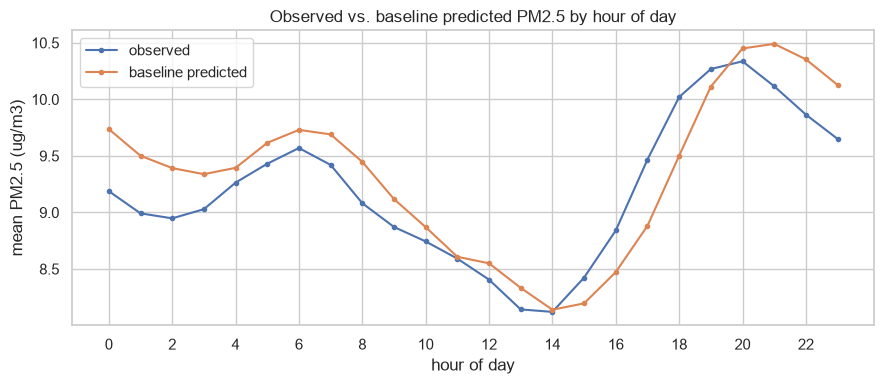

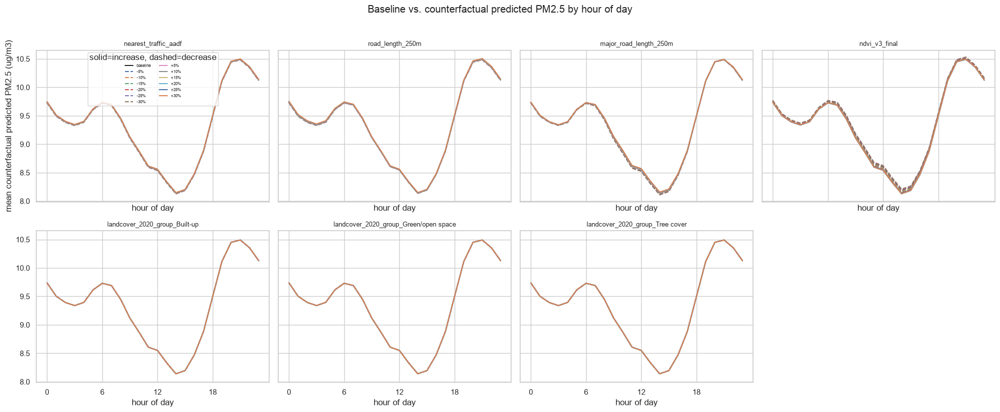

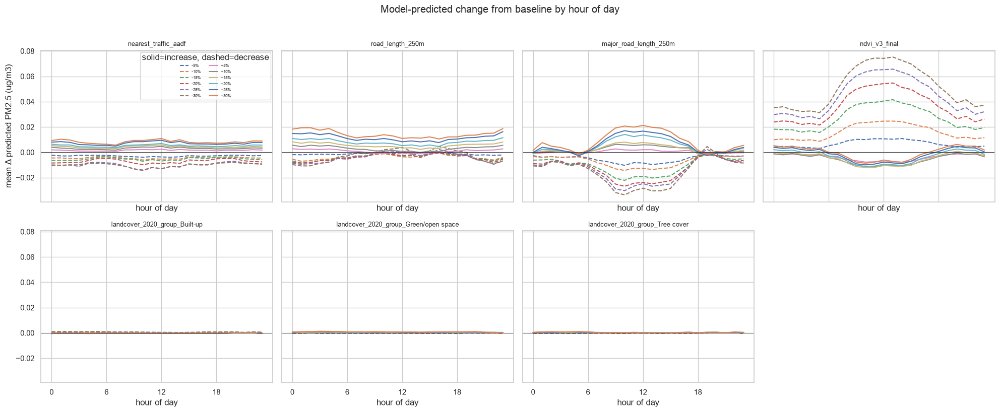

,n,observed,baseline,delta::nearest_traffic_aadf -5%,cf::nearest_traffic_aadf -5%,delta::nearest_traffic_aadf -10%,cf::nearest_traffic_aadf -10%,delta::nearest_traffic_aadf -15%,cf::nearest_traffic_aadf -15%,delta::nearest_traffic_aadf -20%,...,delta::landcover_2020_group_Tree cover +10%,cf::landcover_2020_group_Tree cover +10%,delta::landcover_2020_group_Tree cover +15%,cf::landcover_2020_group_Tree cover +15%,delta::landcover_2020_group_Tree cover +20%,cf::landcover_2020_group_Tree cover +20%,delta::landcover_2020_group_Tree cover +25%,cf::landcover_2020_group_Tree cover +25%,delta::landcover_2020_group_Tree cover +30%,cf::landcover_2020_group_Tree cover +30%
hour,,,,,,,,,,,,,,,,,,,,,
0,6811,9.188,9.737,-0.002,9.734,-0.005,9.732,-0.006,9.730,-0.008,...,0.0,9.737,0.000,9.737,0.000,9.737,0.000,9.737,0.000,9.737
1,6857,8.992,9.501,-0.003,9.498,-0.004,9.497,-0.006,9.495,-0.008,...,0.0,9.502,0.000,9.502,0.001,9.502,0.001,9.502,0.001,9.502
2,6931,8.948,9.392,-0.003,9.389,-0.005,9.387,-0.006,9.386,-0.008,...,0.0,9.392,0.000,9.393,0.000,9.393,0.001,9.393,0.001,9.393
3,6966,9.029,9.338,-0.002,9.336,-0.005,9.333,-0.006,9.332,-0.008,...,0.0,9.339,0.000,9.339,0.000,9.339,0.001,9.339,0.001,9.339
4,6959,9.263,9.394,-0.002,9.392,-0.004,9.390,-0.005,9.389,-0.007,...,0.0,9.395,0.001,9.395,0.001,9.395,0.001,9.395,0.001,9.395
5,6947,9.431,9.615,-0.002,9.613,-0.003,9.612,-0.004,9.611,-0.005,...,0.0,9.616,0.000,9.616,0.000,9.616,0.001,9.616,0.001,9.616
6,6898,9.569,9.730,-0.002,9.728,-0.003,9.727,-0.004,9.727,-0.005,...,0.0,9.730,0.000,9.730,0.000,9.731,0.001,9.731,0.001,9.731
7,6858,9.420,9.690,-0.003,9.687,-0.004,9.686,-0.005,9.686,-0.005,...,0.0,9.690,0.000,9.690,0.000,9.691,0.000,9.691,0.000,9.691
8,6769,9.082,9.447,-0.003,9.444,-0.005,9.442,-0.005,9.442,-0.007,...,0.0,9.447,0.000,9.447,0.000,9.447,0.000,9.448,0.000,9.447


In [29]:
hourly = temporal.groupby("hour").agg(n=("observed", "size"), observed=("observed", "mean"), baseline=("baseline", "mean"))
for name in SCEN_NAMES:
    hourly[f"delta::{name}"] = temporal.groupby("hour")[f"delta::{name}"].mean()
    hourly[f"cf::{name}"] = hourly["baseline"] + hourly[f"delta::{name}"]   # absolute counterfactual predicted PM2.5
hourly.to_csv(os.path.join(OUTPUT_DIR, "hourly_summary.csv"))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hourly.index, hourly["observed"], "-o", ms=3, label="observed")
ax.plot(hourly.index, hourly["baseline"], "-o", ms=3, label="baseline predicted")
ax.set_xlabel("hour of day"); ax.set_ylabel("mean PM2.5 (ug/m3)"); ax.legend(); ax.set_xticks(range(0, 24, 2))
ax.set_title("Observed vs. baseline predicted PM2.5 by hour of day")
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "fig_hourly_observed_vs_baseline.png"), dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=True, sharey=True)
axes_flat = axes.ravel()
for ax, lever in zip(axes_flat, LEVERS):
    ax.plot(hourly.index, hourly["baseline"], "-", color="k", lw=1.4, label="baseline")
    for direction in DIRECTIONS:
        ls = "-" if direction == "increase" else "--"
        sign = "+" if direction == "increase" else "-"
        for pct in PCTS:
            name = scenario_name(lever, direction, pct)
            ax.plot(hourly.index, hourly[f"cf::{name}"], ls, label=f"{sign}{pct}%")
    ax.set_title(lever, fontsize=9); ax.set_xlabel("hour of day"); ax.set_xticks(range(0, 24, 6))
for ax in axes_flat[len(LEVERS):]:
    ax.axis("off")
axes_flat[0].set_ylabel("mean counterfactual predicted PM2.5 (ug/m3)")
axes_flat[0].legend(fontsize=6, ncol=2, title="solid=increase, dashed=decrease")
fig.suptitle("Baseline vs. counterfactual predicted PM2.5 by hour of day", y=1.02)
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "fig_hourly_counterfactual.png"), dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=True, sharey=True)
axes_flat = axes.ravel()
for ax, lever in zip(axes_flat, LEVERS):
    for direction in DIRECTIONS:
        ls = "-" if direction == "increase" else "--"
        sign = "+" if direction == "increase" else "-"
        for pct in PCTS:
            name = scenario_name(lever, direction, pct)
            ax.plot(hourly.index, hourly[f"delta::{name}"], ls, label=f"{sign}{pct}%")
    ax.axhline(0, color="k", lw=0.6); ax.set_title(lever, fontsize=9); ax.set_xlabel("hour of day"); ax.set_xticks(range(0, 24, 6))
for ax in axes_flat[len(LEVERS):]:
    ax.axis("off")
axes_flat[0].set_ylabel("mean \u0394 predicted PM2.5 (ug/m3)")
axes_flat[0].legend(fontsize=6, ncol=2, title="solid=increase, dashed=decrease")
fig.suptitle("Model-predicted change from baseline by hour of day", y=1.02)
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "fig_hourly_delta.png"), dpi=150, bbox_inches="tight"); plt.show()
hourly.round(3)

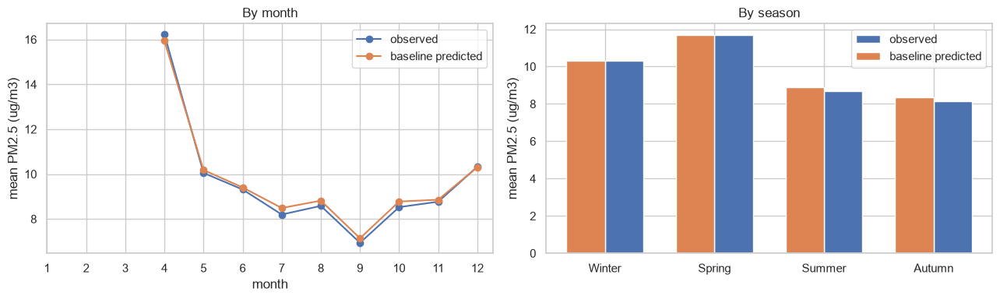

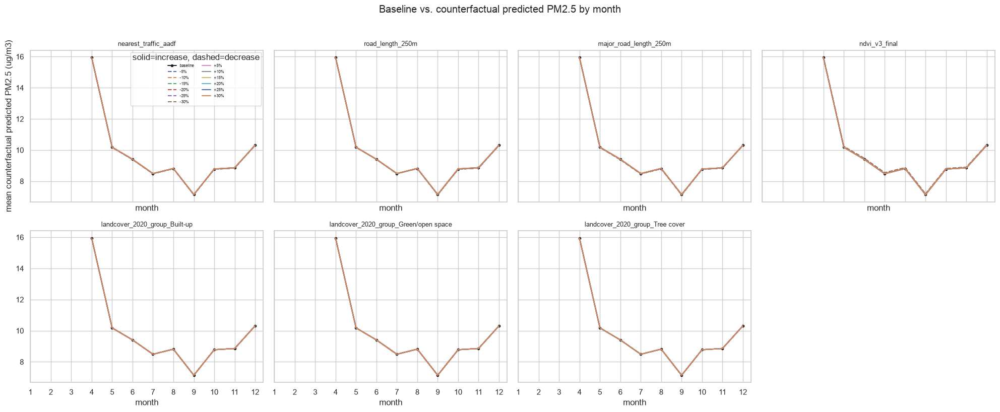

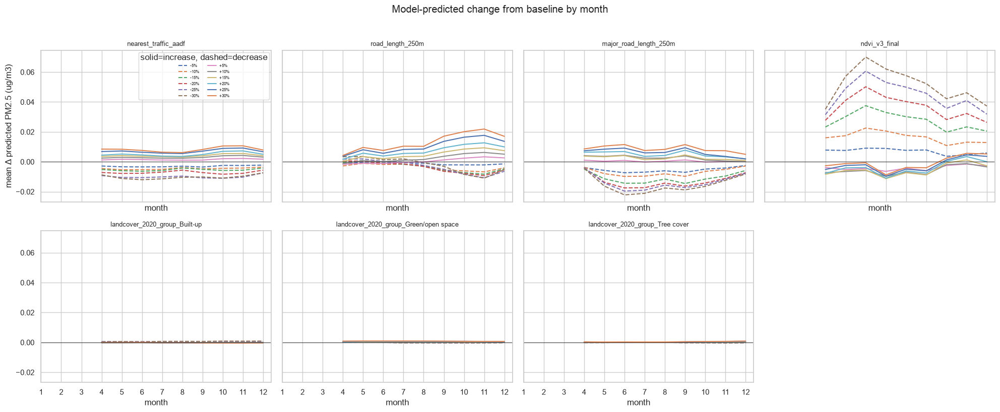

Seasonal summary (observed, baseline, and counterfactual predicted PM2.5; +30%/-30% -- the largest tested magnitude -- per lever):


,n,observed,baseline,cf::nearest_traffic_aadf -30%,cf::nearest_traffic_aadf +30%,cf::road_length_250m -30%,cf::road_length_250m +30%,cf::major_road_length_250m -30%,cf::major_road_length_250m +30%,cf::ndvi_v3_final -30%,cf::ndvi_v3_final +30%,cf::landcover_2020_group_Built-up -30%,cf::landcover_2020_group_Built-up +30%,cf::landcover_2020_group_Green/open space -30%,cf::landcover_2020_group_Green/open space +30%,cf::landcover_2020_group_Tree cover -30%,cf::landcover_2020_group_Tree cover +30%
season,,,,,,,,,,,,,,,,,
Winter,24030,10.325,10.309,10.302,10.317,10.304,10.326,10.301,10.314,10.346,10.314,10.310,10.309,10.309,10.310,10.309,10.310
Spring,26509,11.692,11.708,11.698,11.716,11.712,11.716,11.695,11.718,11.759,11.706,11.709,11.708,11.708,11.709,11.708,11.708
Summer,53663,8.677,8.887,8.875,8.893,8.888,8.896,8.867,8.896,8.950,8.882,8.887,8.886,8.887,8.888,8.887,8.887
Autumn,61167,8.156,8.335,8.325,8.345,8.327,8.355,8.319,8.344,8.382,8.337,8.336,8.335,8.335,8.336,8.335,8.336


In [30]:
monthly = temporal.groupby("month").agg(n=("observed", "size"), observed=("observed", "mean"), baseline=("baseline", "mean"))
for name in SCEN_NAMES:
    monthly[f"delta::{name}"] = temporal.groupby("month")[f"delta::{name}"].mean()
    monthly[f"cf::{name}"] = monthly["baseline"] + monthly[f"delta::{name}"]
monthly.to_csv(os.path.join(OUTPUT_DIR, "monthly_summary.csv"))

seasonal = temporal.groupby("season").agg(n=("observed", "size"), observed=("observed", "mean"), baseline=("baseline", "mean"))
for name in SCEN_NAMES:
    seasonal[f"delta::{name}"] = temporal.groupby("season")[f"delta::{name}"].mean()
    seasonal[f"cf::{name}"] = seasonal["baseline"] + seasonal[f"delta::{name}"]
seasonal = seasonal.reindex(["Winter", "Spring", "Summer", "Autumn"]).dropna(how="all")
seasonal.to_csv(os.path.join(OUTPUT_DIR, "seasonal_summary.csv"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(monthly.index, monthly["observed"], "-o", label="observed")
axes[0].plot(monthly.index, monthly["baseline"], "-o", label="baseline predicted")
axes[0].set_xlabel("month"); axes[0].set_ylabel("mean PM2.5 (ug/m3)"); axes[0].legend(); axes[0].set_xticks(range(1, 13))
axes[0].set_title("By month")
axes[1].bar(seasonal.index, seasonal["observed"], width=0.35, align="edge", label="observed")
axes[1].bar(seasonal.index, seasonal["baseline"], width=-0.35, align="edge", label="baseline predicted")
axes[1].set_ylabel("mean PM2.5 (ug/m3)"); axes[1].legend(); axes[1].set_title("By season")
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "fig_monthly_seasonal_observed_vs_baseline.png"), dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=True, sharey=True)
axes_flat = axes.ravel()
for ax, lever in zip(axes_flat, LEVERS):
    ax.plot(monthly.index, monthly["baseline"], "-o", ms=3, color="k", lw=1.4, label="baseline")
    for direction in DIRECTIONS:
        ls = "-" if direction == "increase" else "--"
        sign = "+" if direction == "increase" else "-"
        for pct in PCTS:
            name = scenario_name(lever, direction, pct)
            ax.plot(monthly.index, monthly[f"cf::{name}"], ls, ms=2, label=f"{sign}{pct}%")
    ax.set_title(lever, fontsize=9); ax.set_xlabel("month"); ax.set_xticks(range(1, 13))
for ax in axes_flat[len(LEVERS):]:
    ax.axis("off")
axes_flat[0].set_ylabel("mean counterfactual predicted PM2.5 (ug/m3)")
axes_flat[0].legend(fontsize=6, ncol=2, title="solid=increase, dashed=decrease")
fig.suptitle("Baseline vs. counterfactual predicted PM2.5 by month", y=1.02)
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "fig_monthly_counterfactual.png"), dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=True, sharey=True)
axes_flat = axes.ravel()
for ax, lever in zip(axes_flat, LEVERS):
    for direction in DIRECTIONS:
        ls = "-" if direction == "increase" else "--"
        sign = "+" if direction == "increase" else "-"
        for pct in PCTS:
            name = scenario_name(lever, direction, pct)
            ax.plot(monthly.index, monthly[f"delta::{name}"], ls, ms=2, label=f"{sign}{pct}%")
    ax.axhline(0, color="k", lw=0.6); ax.set_title(lever, fontsize=9); ax.set_xlabel("month"); ax.set_xticks(range(1, 13))
for ax in axes_flat[len(LEVERS):]:
    ax.axis("off")
axes_flat[0].set_ylabel("mean \u0394 predicted PM2.5 (ug/m3)")
axes_flat[0].legend(fontsize=6, ncol=2, title="solid=increase, dashed=decrease")
fig.suptitle("Model-predicted change from baseline by month", y=1.02)
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "fig_monthly_delta.png"), dpi=150, bbox_inches="tight"); plt.show()

print("Seasonal summary (observed, baseline, and counterfactual predicted PM2.5; +30%/-30% -- the largest tested magnitude -- per lever):")
_headline_cols = [f"cf::{scenario_name(l, d, 30)}" for l in LEVERS for d in DIRECTIONS]
seasonal[["n", "observed", "baseline"] + _headline_cols].round(3)

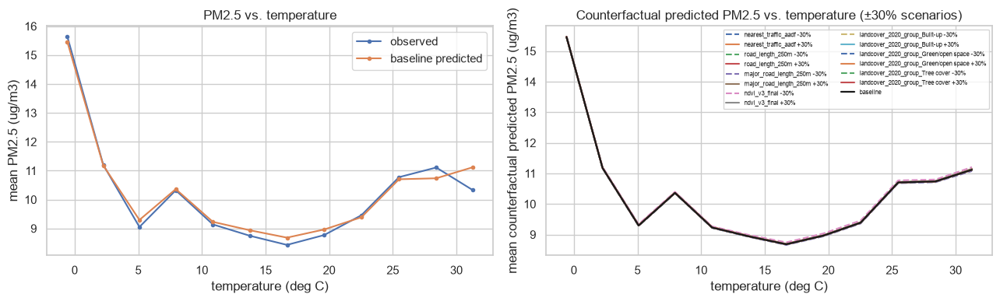

,temp_bin_mean,n,observed,baseline,delta::nearest_traffic_aadf -5%,cf::nearest_traffic_aadf -5%,delta::nearest_traffic_aadf -10%,cf::nearest_traffic_aadf -10%,delta::nearest_traffic_aadf -15%,cf::nearest_traffic_aadf -15%,...,delta::landcover_2020_group_Tree cover +10%,cf::landcover_2020_group_Tree cover +10%,delta::landcover_2020_group_Tree cover +15%,cf::landcover_2020_group_Tree cover +15%,delta::landcover_2020_group_Tree cover +20%,cf::landcover_2020_group_Tree cover +20%,delta::landcover_2020_group_Tree cover +25%,cf::landcover_2020_group_Tree cover +25%,delta::landcover_2020_group_Tree cover +30%,cf::landcover_2020_group_Tree cover +30%
temp_bin,,,,,,,,,,,,,,,,,,,,,
"(-2.552, 0.421]",-0.575,1581,15.644,15.461,-0.001,15.460,-0.002,15.459,-0.003,15.458,...,-0.0,15.461,-0.0,15.461,-0.0,15.461,0.000,15.461,-0.000,15.460
"(0.421, 3.392]",2.255,4435,11.199,11.178,-0.002,11.175,-0.003,11.174,-0.005,11.173,...,0.0,11.178,0.0,11.178,0.0,11.178,0.001,11.178,0.000,11.178
"(3.392, 6.364]",5.093,11318,9.052,9.296,-0.002,9.294,-0.003,9.292,-0.004,9.291,...,0.0,9.296,0.0,9.296,0.0,9.296,0.001,9.296,0.001,9.297
"(6.364, 9.335]",7.948,18026,10.321,10.362,-0.002,10.359,-0.004,10.358,-0.005,10.357,...,0.0,10.362,0.0,10.362,0.0,10.362,0.000,10.362,0.001,10.362
"(9.335, 12.307]",10.866,31952,9.141,9.230,-0.003,9.227,-0.004,9.225,-0.005,9.224,...,0.0,9.230,0.0,9.230,0.0,9.230,0.001,9.230,0.001,9.230
"(12.307, 15.279]",13.796,36156,8.745,8.937,-0.003,8.934,-0.004,8.932,-0.005,8.931,...,0.0,8.937,0.0,8.937,0.0,8.937,0.000,8.937,0.001,8.937
"(15.279, 18.25]",16.690,27790,8.432,8.683,-0.004,8.680,-0.005,8.678,-0.006,8.677,...,0.0,8.683,0.0,8.683,0.0,8.684,0.000,8.683,0.000,8.684
"(18.25, 21.222]",19.614,19159,8.773,8.966,-0.003,8.963,-0.005,8.961,-0.006,8.960,...,0.0,8.966,0.0,8.966,0.0,8.966,0.000,8.966,0.000,8.966
"(21.222, 24.193]",22.534,9484,9.458,9.388,-0.004,9.384,-0.005,9.383,-0.006,9.381,...,0.0,9.388,-0.0,9.388,0.0,9.388,-0.000,9.388,0.000,9.388


In [31]:
N_TEMP_BINS = 12
temp_edges = np.linspace(temporal["temperature"].min(), temporal["temperature"].max(), N_TEMP_BINS + 1)
temporal["temp_bin"] = pd.cut(temporal["temperature"], temp_edges, include_lowest=True)
temp_mid = temporal.groupby("temp_bin", observed=True)["temperature"].mean()

temp_summary = temporal.groupby("temp_bin", observed=True).agg(n=("observed", "size"), observed=("observed", "mean"), baseline=("baseline", "mean"))
for name in SCEN_NAMES:
    temp_summary[f"delta::{name}"] = temporal.groupby("temp_bin", observed=True)[f"delta::{name}"].mean()
    temp_summary[f"cf::{name}"] = temp_summary["baseline"] + temp_summary[f"delta::{name}"]
temp_summary.insert(0, "temp_bin_mean", temp_mid)
temp_summary.to_csv(os.path.join(OUTPUT_DIR, "temperature_bin_summary.csv"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(temp_summary["temp_bin_mean"], temp_summary["observed"], "-o", ms=3, label="observed")
axes[0].plot(temp_summary["temp_bin_mean"], temp_summary["baseline"], "-o", ms=3, label="baseline predicted")
axes[0].set_xlabel("temperature (deg C)"); axes[0].set_ylabel("mean PM2.5 (ug/m3)"); axes[0].legend()
axes[0].set_title("PM2.5 vs. temperature")
for lever in LEVERS:
    for direction in DIRECTIONS:
        sign = "+" if direction == "increase" else "-"
        name = scenario_name(lever, direction, 30)
        ls = "-" if direction == "increase" else "--"
        axes[1].plot(temp_summary["temp_bin_mean"], temp_summary[f"cf::{name}"], ls, ms=2, label=f"{lever} {sign}30%")
axes[1].plot(temp_summary["temp_bin_mean"], temp_summary["baseline"], "-", ms=3, color="k", lw=1.6, label="baseline")
axes[1].set_xlabel("temperature (deg C)"); axes[1].set_ylabel("mean counterfactual predicted PM2.5 (ug/m3)")
axes[1].legend(fontsize=6, ncol=2); axes[1].set_title("Counterfactual predicted PM2.5 vs. temperature (\u00b130% scenarios)")
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "fig_temperature.png"), dpi=150, bbox_inches="tight"); plt.show()
temp_summary.round(3)

In [32]:
import shapely
from shapely.geometry import Polygon, MultiPolygon, box, mapping
from shapely.ops import unary_union, transform as shp_transform
from shapely.validation import make_valid
from pyproj import Transformer

print("shapely", shapely.__version__)

BOROUGH_CSV_PATH = "london_boroughs.csv"
STUDY_BBOX_LONLAT = (-0.510, 51.286, 0.334, 51.692)   # min_lon, min_lat, max_lon, max_lat

BNG_TO_WGS84 = Transformer.from_crs("EPSG:27700", "EPSG:4326", always_xy=True)
WGS84_TO_BNG = Transformer.from_crs("EPSG:4326", "EPSG:27700", always_xy=True)

def to_wgs84(geom):
    return shp_transform(lambda x, y: BNG_TO_WGS84.transform(x, y), geom)

def to_bng(geom):
    return shp_transform(lambda x, y: WGS84_TO_BNG.transform(x, y), geom)


def densified_bbox_bng(bbox_lonlat, n_per_edge=40):
    """The study bbox is a rectangle in WGS84; densify its edges before projecting to BNG so the
    reprojected boundary follows the true (slightly curved, under EPSG:27700) shape rather than
    straight corner-to-corner lines."""
    lon0, lat0, lon1, lat1 = bbox_lonlat
    pts = []
    for lon in np.linspace(lon0, lon1, n_per_edge): pts.append((lon, lat0))
    for lat in np.linspace(lat0, lat1, n_per_edge): pts.append((lon1, lat))
    for lon in np.linspace(lon1, lon0, n_per_edge): pts.append((lon, lat1))
    for lat in np.linspace(lat1, lat0, n_per_edge): pts.append((lon0, lat))
    ring = Polygon(pts)
    return to_bng(ring)

STUDY_BOX_BNG = densified_bbox_bng(STUDY_BBOX_LONLAT)
STUDY_BOX_WGS84 = box(*STUDY_BBOX_LONLAT)
print(f"Study bounding box (WGS84): {STUDY_BBOX_LONLAT}")
print(f"Study bounding box area (BNG, densified reprojection): {STUDY_BOX_BNG.area / 1e6:,.1f} km^2")

shapely 2.1.2
Study bounding box (WGS84): (-0.51, 51.286, 0.334, 51.692)
Study bounding box area (BNG, densified reprojection): 2,647.2 km^2


In [33]:
import numpy as np
import pandas as pd

from shapely.geometry import Polygon, MultiPolygon
from shapely.ops import unary_union
from shapely.validation import make_valid


boundary_raw = pd.read_csv(BOROUGH_CSV_PATH)

assert {"borough", "x", "y"}.issubset(boundary_raw.columns)

print(
    f"Boundary file: {len(boundary_raw):,} rows, "
    f"{boundary_raw['borough'].nunique()} boroughs"
)


def split_boundary_parts(group):
    """
    Split one borough's coordinate rows into separate boundary parts.

    Rows containing NaN in x or y are treated as separators.
    """
    parts = []
    current = []

    for x, y in zip(group["x"], group["y"]):

        # NaN row = separator
        if pd.isna(x) or pd.isna(y):
            if len(current) >= 3:
                parts.append(current)
            current = []
            continue

        current.append((float(x), float(y)))

    # Capture final part
    if len(current) >= 3:
        parts.append(current)

    return parts


def polygon_from_part(coords):
    """
    Convert one coordinate sequence into a valid polygon.
    """
    coords = list(coords)

    # Remove consecutive duplicate points
    cleaned = [coords[0]]

    for p in coords[1:]:
        if p != cleaned[-1]:
            cleaned.append(p)

    if len(cleaned) < 3:
        return None

    # Explicitly close the ring
    if cleaned[0] != cleaned[-1]:
        cleaned.append(cleaned[0])

    if len(cleaned) < 4:
        return None

    try:
        poly = Polygon(cleaned)
    except Exception:
        return None

    # Repair invalid geometry if necessary
    if not poly.is_valid:
        poly = make_valid(poly)

    return poly


borough_records = []

for borough, group in boundary_raw.groupby("borough", sort=True):

    parts = split_boundary_parts(group)

    polygons = []

    for coords in parts:
        geom = polygon_from_part(coords)

        if geom is None:
            continue

        # make_valid() can potentially return MultiPolygon/GeometryCollection
        if geom.geom_type == "Polygon":
            polygons.append(geom)

        elif geom.geom_type == "MultiPolygon":
            polygons.extend(list(geom.geoms))

    if not polygons:
        borough_geom = None

    elif len(polygons) == 1:
        borough_geom = polygons[0]

    else:
        borough_geom = unary_union(polygons)

    if borough_geom is not None and not borough_geom.is_valid:
        borough_geom = make_valid(borough_geom)

    borough_records.append({
        "borough": borough,
        "geometry_bng": borough_geom,
        "n_parts": len(polygons),
        "area_km2": (
            borough_geom.area / 1e6
            if borough_geom is not None
            else 0.0
        ),
        "is_valid": (
            borough_geom is not None
            and borough_geom.is_valid
        )
    })


boroughs_df = pd.DataFrame(borough_records)

print(f"\nReconstructed {len(boroughs_df)} borough geometries:")
print(
    f"  valid geometries : "
    f"{boroughs_df['is_valid'].sum()} / {len(boroughs_df)}"
)
print(
    f"  multipart        : "
    f"{(boroughs_df['n_parts'] > 1).sum()}"
)

assert len(boroughs_df) == 32
assert boroughs_df["is_valid"].all()

boroughs_df[
    ["borough", "n_parts", "area_km2", "is_valid"]
].sort_values("borough").round(2)

Boundary file: 45,341 rows, 32 boroughs

Reconstructed 32 borough geometries:
  valid geometries : 32 / 32
  multipart        : 0


,borough,n_parts,area_km2,is_valid
0,Barking & Dagenham,1,37.80,True
1,Barnet,1,86.75,True
2,Bexley,1,64.29,True
3,Brent,1,43.23,True
4,Bromley,1,150.13,True
5,Camden,1,21.79,True
6,Croydon,1,86.50,True
7,Ealing,1,55.54,True
8,Enfield,1,82.20,True
9,Greenwich,1,50.44,True


In [34]:
boroughs_df["geometry_clipped_bng"] = boroughs_df["geometry_bng"].apply(lambda g: g.intersection(STUDY_BOX_BNG) if g is not None else None)
boroughs_df["overlap_km2"] = boroughs_df["geometry_clipped_bng"].apply(lambda g: g.area / 1e6 if g is not None else 0.0)
boroughs_df["overlaps_study_area"] = boroughs_df["overlap_km2"] > 0
boroughs_df["clip_fraction"] = np.where(boroughs_df["area_km2"] > 0, boroughs_df["overlap_km2"] / boroughs_df["area_km2"], 0.0)

excluded = boroughs_df.loc[~boroughs_df["overlaps_study_area"], "borough"].tolist()
clipped = boroughs_df.loc[boroughs_df["overlaps_study_area"] & (boroughs_df["clip_fraction"] < 0.999), "borough"].tolist()

print(f"Boroughs with NO overlap with the study area (excluded from all PM2.5 analysis): {excluded or 'none'}")
print(f"Boroughs partially clipped to the study-area boundary: {clipped or 'none'}")

BOROUGHS = boroughs_df.loc[boroughs_df["overlaps_study_area"]].reset_index(drop=True)
BOROUGHS["geometry_wgs84"] = BOROUGHS["geometry_clipped_bng"].apply(to_wgs84)
print(f"\n{len(BOROUGHS)} boroughs retained for the PM2.5 analysis (of {len(boroughs_df)} in the boundary file).")
BOROUGHS[["borough", "area_km2", "overlap_km2", "clip_fraction"]].sort_values("borough").round(3)

Boroughs with NO overlap with the study area (excluded from all PM2.5 analysis): none
Boroughs partially clipped to the study-area boundary: none

32 boroughs retained for the PM2.5 analysis (of 32 in the boundary file).


,borough,area_km2,overlap_km2,clip_fraction
0,Barking & Dagenham,37.799,37.799,1.0
1,Barnet,86.748,86.748,1.0
2,Bexley,64.286,64.286,1.0
3,Brent,43.233,43.233,1.0
4,Bromley,150.135,150.135,1.0
5,Camden,21.789,21.789,1.0
6,Croydon,86.496,86.496,1.0
7,Ealing,55.544,55.544,1.0
8,Enfield,82.200,82.200,1.0
9,Greenwich,50.439,50.439,1.0


In [35]:
loc_coords = df_temporal.groupby("location_id")[[LAT_COL, LON_COL]].median().reset_index()
loc_coords.columns = ["location_id", "latitude", "longitude"]
xy_bng = np.array([WGS84_TO_BNG.transform(lo, la) for lo, la in zip(loc_coords["longitude"], loc_coords["latitude"])])
loc_coords["x_bng"], loc_coords["y_bng"] = xy_bng[:, 0], xy_bng[:, 1]
loc_coords["in_study_area"] = loc_coords.apply(
    lambda r: STUDY_BOX_WGS84.contains(shapely.Point(r["longitude"], r["latitude"])), axis=1)

def assign_borough(row):
    if not row["in_study_area"]:
        return "Outside study area"
    pt = shapely.Point(row["x_bng"], row["y_bng"])
    for _, b in BOROUGHS.iterrows():
        if b["geometry_clipped_bng"].contains(pt):
            return b["borough"]
    return "Unassigned (inside study area, no borough match)"

loc_coords["borough"] = loc_coords.apply(assign_borough, axis=1)

location_borough_lookup = loc_coords[["location_id", "latitude", "longitude", "borough", "in_study_area"]]
location_borough_lookup.to_csv(os.path.join(OUTPUT_DIR, "location_id_to_borough.csv"), index=False)

print(location_borough_lookup["borough"].value_counts().to_string())
print(f"\nSaved: {os.path.join(OUTPUT_DIR, 'location_id_to_borough.csv')}  ({len(location_borough_lookup)} physical locations)")

borough
Richmond                                            29
Wandsworth                                          19
Westminster                                         17
Southwark                                           16
Camden                                              15
Tower Hamlets                                       14
Islington                                           11
Greenwich                                            9
Brent                                                8
Unassigned (inside study area, no borough match)     8
Lambeth                                              8
Kensington & Chelsea                                 8
Lewisham                                             6
Newham                                               6
Merton                                               5
Bexley                                               5
Hackney                                              5
Barnet                                               4
Ki

In [36]:
# Confirm the main dataset was never modified by this section.
integrity_spatial = {
    "df_original still has its original column set (no 'borough' column added)": "borough" not in df_original.columns,
    "test_block / train_block still have their original column set (no 'borough' column added)":
        ("borough" not in test_block.columns) and ("borough" not in train_block.columns),
}
for k, v in integrity_spatial.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(integrity_spatial.values())

PASS  df_original still has its original column set (no 'borough' column added)
PASS  test_block / train_block still have their original column set (no 'borough' column added)


In [37]:
test_borough = test_block[["location_id", TIME_COL]].merge(location_borough_lookup[["location_id", "borough"]], on="location_id", how="left")
test_borough["observed"] = y_test_w
test_borough["baseline"] = baseline_predictions
test_borough["hour"] = test_block[TIME_COL].dt.hour.to_numpy()
test_borough["month"] = test_block[TIME_COL].dt.month.to_numpy()
for name in SCEN_NAMES:
    test_borough[f"cf::{name}"] = baseline_predictions + scenario_deltas[name]       # counterfactual prediction
    test_borough[f"delta::{name}"] = scenario_deltas[name]

IN_STUDY_BOROUGHS = sorted(set(BOROUGHS["borough"]) & set(test_borough["borough"].dropna()))
tb = test_borough[test_borough["borough"].isin(IN_STUDY_BOROUGHS)].copy()
print(f"Test rows with a borough inside the study area: {len(tb):,} / {len(test_borough):,} "
      f"({tb['location_id'].nunique()} physical locations across {len(IN_STUDY_BOROUGHS)} boroughs)")

Test rows with a borough inside the study area: 157,775 / 165,369 (44 physical locations across 18 boroughs)


In [38]:
# Create borough summary for mapping

# Count observations for each physical location
location_observation_counts = (
    df_temporal
    .groupby("location_id")
    .size()
    .rename("n_observations")
    .reset_index()
)

# Attach each physical location to its borough
location_summary = location_borough_lookup[
    ["location_id", "borough", "in_study_area"]
].merge(
    location_observation_counts,
    on="location_id",
    how="left"
)

# Count physical locations and observations by borough
borough_summary = (
    location_summary[
        location_summary["in_study_area"]
    ]
    .groupby("borough", dropna=False)
    .agg(
        n_locations=("location_id", "nunique"),
        n_observations=("n_observations", "sum")
    )
    .reset_index()
)

# Replace missing observation counts with zero
borough_summary["n_observations"] = (
    borough_summary["n_observations"]
    .fillna(0)
    .astype(int)
)

display(
    borough_summary.sort_values("borough")
)

,borough,n_locations,n_observations
0,Barking & Dagenham,2,12298
1,Barnet,4,29225
2,Bexley,5,46747
3,Brent,8,115319
4,Bromley,1,13852
5,Camden,15,88554
6,Croydon,2,22470
7,Ealing,3,16776
8,Enfield,3,11744
9,Greenwich,9,89651


In [39]:
CENTRAL_LONDON_BOROUGHS = [
    "Camden",
    "Hackney",
    "Islington",
    "Kensington & Chelsea",
    "Lambeth",
    "Westminster",
]

In [40]:
CENTRAL_LONDON_BOROUGHS = ["Westminster", "Camden", "Islington", "Tower Hamlets", "Hackney", "Southwark", "Lambeth"]
BOROUGHS["borough"] = BOROUGHS["borough"].astype(str).str.strip()   # re-assert normalization here too

_missing_cl = [b for b in CENTRAL_LONDON_BOROUGHS if b not in set(BOROUGHS["borough"])]
assert not _missing_cl, f"Central London's surrounding boroughs not found after clipping: {_missing_cl}"

central_parts = BOROUGHS[BOROUGHS["borough"].isin(CENTRAL_LONDON_BOROUGHS)].copy()
assert len(central_parts) == 7, f"Expected 7, found {len(central_parts)}: {central_parts['borough'].tolist()}"

CENTRAL_LONDON_RADIUS_M = 2200   # explicit, guaranteed-visible core radius in metres

_centroid_bng = unary_union([to_bng(g) for g in central_parts["geometry_wgs84"]]).centroid
central_london_geom_bng = _centroid_bng.buffer(CENTRAL_LONDON_RADIUS_M)

# Validate before converting to WGS84 so problems surface here.
assert not central_london_geom_bng.is_empty, "Central London geometry (BNG) is empty."
assert central_london_geom_bng.is_valid, "Central London geometry (BNG) is invalid."
print(f"Central London (BNG): area = {central_london_geom_bng.area/1e6:.2f} km^2, "
      f"bounds = {central_london_geom_bng.bounds}")

CENTRAL_LONDON_GEOM = to_wgs84(central_london_geom_bng)
if not CENTRAL_LONDON_GEOM.is_valid:
    CENTRAL_LONDON_GEOM = make_valid(CENTRAL_LONDON_GEOM)
assert not CENTRAL_LONDON_GEOM.is_empty, "Central London geometry (WGS84) is empty after reprojection."
print(f"Central London (WGS84): geom_type = {CENTRAL_LONDON_GEOM.geom_type}, "
      f"bounds (lon,lat) = {CENTRAL_LONDON_GEOM.bounds}")

# Sanity: bounds must sit inside the study bbox, or the map will never show it in view.
_lon0, _lat0, _lon1, _lat1 = STUDY_BBOX_LONLAT
_glon0, _glat0, _glon1, _glat1 = CENTRAL_LONDON_GEOM.bounds
assert _lon0 <= _glon0 and _glon1 <= _lon1 and _lat0 <= _glat0 and _glat1 <= _lat1, \
    "Central London geometry falls outside the study bounding box. It will never render on the map."
print("Central London geometry passes all validity/bounds checks.")

Central London (BNG): area = 15.18 km^2, bounds = (529600.0285561405, 178351.5775003571, 534000.0285561405, 182751.5775003571)
Central London (WGS84): geom_type = Polygon, bounds (lon,lat) = (-0.1339109230382445, 51.488760702101224, -0.07054681404306598, 51.52830136751466)
Central London geometry passes all validity/bounds checks.


In [41]:
# Central London as a circular core region (stats by point-in-polygon)
from shapely.geometry import Point

BOROUGHS["borough"] = BOROUGHS["borough"].astype(str).str.strip()

# Count observations per location
obs_counts = (
    df_temporal.groupby("location_id").size()
    .rename("n_observations").reset_index()
)

# Locations (with coordinates) that fall inside the circle
pts = loc_coords[["location_id", "latitude", "longitude"]].drop_duplicates("location_id").merge(
    obs_counts, on="location_id", how="left"
)
pts["n_observations"] = pts["n_observations"].fillna(0)

in_circle = pts[[
    CENTRAL_LONDON_GEOM.contains(Point(lon, lat))
    for lon, lat in zip(pts["longitude"], pts["latitude"])
]]

central_london_row = pd.DataFrame({
    "borough": ["Central London"],
    "geometry_wgs84": [CENTRAL_LONDON_GEOM],
    "n_locations": [in_circle["location_id"].nunique()],
    "n_observations": [int(in_circle["n_observations"].sum())],
})

# Merge the 32 boroughs with stats first, then append Central London
boroughs_merged = BOROUGHS[["borough", "geometry_wgs84"]].merge(
    borough_summary, on="borough", how="left"
)
borough_map_df = pd.concat([boroughs_merged, central_london_row], ignore_index=True)

cols = ["n_locations", "n_observations"]
borough_map_df[cols] = borough_map_df[cols].fillna(0).astype(int)

central_london_point = CENTRAL_LONDON_GEOM.representative_point()

assert len(borough_map_df) == 33
assert not borough_map_df[cols].isna().any().any()
print(borough_map_df.loc[borough_map_df["borough"] == "Central London", cols].to_string(index=False))

 n_locations  n_observations
          26          177340


In [42]:
value_cols = [
    "baseline"
] + [
    c for c in tb.columns
    if c.startswith("cf::")
]

print(f"Number of value columns: {len(value_cols)}")
print(value_cols)

Number of value columns: 85
['baseline', 'cf::nearest_traffic_aadf -5%', 'cf::nearest_traffic_aadf -10%', 'cf::nearest_traffic_aadf -15%', 'cf::nearest_traffic_aadf -20%', 'cf::nearest_traffic_aadf -25%', 'cf::nearest_traffic_aadf -30%', 'cf::nearest_traffic_aadf +5%', 'cf::nearest_traffic_aadf +10%', 'cf::nearest_traffic_aadf +15%', 'cf::nearest_traffic_aadf +20%', 'cf::nearest_traffic_aadf +25%', 'cf::nearest_traffic_aadf +30%', 'cf::road_length_250m -5%', 'cf::road_length_250m -10%', 'cf::road_length_250m -15%', 'cf::road_length_250m -20%', 'cf::road_length_250m -25%', 'cf::road_length_250m -30%', 'cf::road_length_250m +5%', 'cf::road_length_250m +10%', 'cf::road_length_250m +15%', 'cf::road_length_250m +20%', 'cf::road_length_250m +25%', 'cf::road_length_250m +30%', 'cf::major_road_length_250m -5%', 'cf::major_road_length_250m -10%', 'cf::major_road_length_250m -15%', 'cf::major_road_length_250m -20%', 'cf::major_road_length_250m -25%', 'cf::major_road_length_250m -30%', 'cf::major

In [43]:
_headline = (
    [f"cf::{scenario_name(l, d, 30)}" for l in LEVERS for d in DIRECTIONS]
    + [f"delta::{scenario_name(l, d, 30)}" for l in LEVERS for d in DIRECTIONS]
)

# Include observed PM2.5, baseline predictions, counterfactual predictions,
# and counterfactual deltas in the borough summaries.
value_cols = (
    ["observed", "baseline"]
    + [c for c in tb.columns if c.startswith("cf::")]
    + [c for c in tb.columns if c.startswith("delta::")]
)

# Keep only columns that actually exist in tb
value_cols = list(dict.fromkeys(
    c for c in value_cols if c in tb.columns
))

# Borough by hour

borough_hour = (
    tb.groupby(["borough", "hour"])
      .agg(n=("observed", "size"))
)

per_loc_hour = (
    tb.groupby(["location_id", "borough", "hour"])[value_cols]
      .mean()
      .reset_index()
)

borough_hour_values = (
    per_loc_hour
    .groupby(["borough", "hour"])[value_cols]
    .mean()
)

borough_hour = borough_hour.join(borough_hour_values)

borough_hour.to_csv(
    os.path.join(OUTPUT_DIR, "borough_by_hour.csv")
)

# Borough by month

borough_month = (
    tb.groupby(["borough", "month"])
      .agg(n=("observed", "size"))
)

per_loc_month = (
    tb.groupby(["location_id", "borough", "month"])[value_cols]
      .mean()
      .reset_index()
)

borough_month_values = (
    per_loc_month
    .groupby(["borough", "month"])[value_cols]
    .mean()
)

borough_month = borough_month.join(borough_month_values)

borough_month.to_csv(
    os.path.join(OUTPUT_DIR, "borough_by_month.csv")
)

# Preview

print(
    f"Saved borough_by_hour.csv ({borough_hour.shape[0]} rows) "
    f"and borough_by_month.csv ({borough_month.shape[0]} rows)."
)

preview_cols = [
    c for c in ["n", "observed", "baseline"] + _headline
    if c in borough_hour.columns
]

display(
    borough_hour[preview_cols]
    .round(3)
    .head(10)
)

Saved borough_by_hour.csv (432 rows) and borough_by_month.csv (133 rows).


n  observed  baseline  cf::nearest_traffic_aadf -30%  \
borough hour                                                           
Camden  0     284    10.927    12.285                         12.287   
        1     285     8.481    10.724                         10.731   
        2     287     8.448     8.834                          8.836   
        3     288     8.352     8.910                          8.914   
        4     284     8.363     8.750                          8.754   
        5     283     7.973     8.643                          8.647   
        6     279     8.018     8.518                          8.522   
        7     277     8.428     8.377                          8.379   
        8     272     8.059     8.340                          8.343   
        9     272     8.733     8.350                          8.350   

              cf::nearest_traffic_aadf +30%  cf::road_length_250m -30%  \
borough hour                                                             
Camden  0                            12.289                     12.260   
        1                            10.727                     10.706   
        2                             8.839                      8.801   
        3                             8.915                      8.909   
        4                             8.754                      8.755   
        5                             8.652                      8.649   
        6                             8.525                      8.528   
        7                             8.380                      8.380   
        8                             8.342                      8.325   
        9                             8.351                      8.366   

              cf::road_length_250m +30%  cf::major_road_length_250m -30%  \
borough hour                                                               
Camden  0                        12.293                           12.244   
        1                        10.737                           10.679   
        2                         8.852                            8.757   
        3                         8.913                            8.842   
        4                         8.768                            8.701   
        5                         8.643                            8.587   
        6                         8.520                            8.441   
        7                         8.377                            8.306   
        8                         8.357                            8.286   
        9                         8.362                            8.321   

              cf::major_road_length_250m +30%  cf::ndvi_v3_final -30%  ...  \
borough hour                                                           ...   
Camden  0                              12.292                  12.296  ...   
        1                              10.734                  10.742  ...   
        2                               8.851                   8.842  ...   
        3                               8.927                   8.915  ...   
        4                               8.782                   8.763  ...   
        5                               8.666                   8.655  ...   
        6                               8.543                   8.531  ...   
        7                               8.407                   8.400  ...   
        8                               8.365                   8.372  ...   
        9                               8.380                   8.379  ...   

              delta::major_road_length_250m -30%  \
borough hour                                       
Camden  0                                 -0.041   
        1                                 -0.045   
        2                                 -0.077   
        3                                 -0.068   
        4                                 -0.049   
        5                                 -0.056

In [44]:
# Borough-level counterfactual delta summary

# Average each counterfactual delta across locations within each borough
borough_delta = (
    tb.groupby(["location_id", "borough"])[
        [f"delta::{n}" for n in SCEN_NAMES]
    ]
    .mean()
    .reset_index()
    .groupby("borough")[
        [f"delta::{n}" for n in SCEN_NAMES]
    ]
    .mean()
)

# Convert scenario columns to long format
long_delta = borough_delta.copy()
long_delta.columns = SCEN_NAMES

long_delta = (
    long_delta
    .reset_index()
    .melt(
        id_vars="borough",
        var_name="scenario",
        value_name="mean_delta"
    )
)

_parsed = long_delta["scenario"].str.extract(
    r"^(?P<lever>.*) (?P<sign>[+-])(?P<pct>\d+)%$"
)

long_delta = pd.concat(
    [long_delta, _parsed],
    axis=1
)

long_delta["pct"] = long_delta["pct"].astype(int)
long_delta["direction"] = long_delta["sign"].map({
    "-": "decrease",
    "+": "increase"
})

display(long_delta.head())

,borough,scenario,mean_delta,lever,sign,pct,direction
0,Camden,nearest_traffic_aadf -5%,0.000573,nearest_traffic_aadf,-,5,decrease
1,Croydon,nearest_traffic_aadf -5%,0.000027,nearest_traffic_aadf,-,5,decrease
2,Ealing,nearest_traffic_aadf -5%,-0.000112,nearest_traffic_aadf,-,5,decrease
3,Enfield,nearest_traffic_aadf -5%,-0.004344,nearest_traffic_aadf,-,5,decrease
4,Hackney,nearest_traffic_aadf -5%,-0.002313,nearest_traffic_aadf,-,5,decrease


In [45]:
import plotly
import plotly.graph_objects as go
import plotly.express as px

MAPS_DIR = os.path.join(OUTPUT_DIR, "maps")
os.makedirs(MAPS_DIR, exist_ok=True)

# Plotly >= 6.1 renamed the free (token-less) map traces/layout: Scattermapbox -> Scattermap,
# Choroplethmapbox -> Choroplethmap, and the `mapbox=` layout key -> `map=`. Support either.
if hasattr(go, "Scattermapbox"):
    ScatterMapTrace, ChoroplethMapTrace, MAP_LAYOUT_KEY, MAPBOX_STYLE = go.Scattermapbox, go.Choroplethmapbox, "mapbox", "open-street-map"
else:
    ScatterMapTrace, ChoroplethMapTrace, MAP_LAYOUT_KEY, MAPBOX_STYLE = go.Scattermap, go.Choroplethmap, "map", "open-street-map"
print(f"Plotly {plotly.__version__}: using {ScatterMapTrace.__name__} / {ChoroplethMapTrace.__name__} (layout key '{MAP_LAYOUT_KEY}')")

MAP_CENTER = {"lat": (STUDY_BBOX_LONLAT[1] + STUDY_BBOX_LONLAT[3]) / 2, "lon": (STUDY_BBOX_LONLAT[0] + STUDY_BBOX_LONLAT[2]) / 2}


def polygon_traces(geom, name, line_color, fill_color=None, hover_text=None, legendgroup=None, showlegend=True):
    """Yield Scattermapbox traces for a (Multi)Polygon in WGS84: one filled trace per exterior ring,
    one unfilled dashed trace per interior ring (hole). Scattermapbox has no native hole support,
    so the hole boundary is drawn as an outline on top rather than actually punched out of the fill."""
    parts = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]
    traces = []
    first = True
    for part in parts:
        x, y = part.exterior.coords.xy
        traces.append(ScatterMapTrace(
            lon=list(x), lat=list(y), mode="lines", fill="toself" if fill_color else "none",
            fillcolor=fill_color, line=dict(color=line_color, width=1.4),
            name=name, legendgroup=legendgroup or name, showlegend=showlegend and first,
            text=hover_text, hoverinfo="text" if hover_text else "skip"))
        first = False
        for interior in part.interiors:
            xi, yi = interior.coords.xy
            traces.append(ScatterMapTrace(lon=list(xi), lat=list(yi), mode="lines",
                                           line=dict(color=line_color, width=1.0),
                                           name=f"{name} (hole)", legendgroup=legendgroup or name,
                                           showlegend=False, hoverinfo="skip"))
    return traces


def borough_geojson(frame, geom_col="geometry_wgs84", name_col="borough"):
    return {"type": "FeatureCollection", "features": [
        {"type": "Feature", "properties": {name_col: row[name_col]}, "geometry": mapping(row[geom_col])}
        for _, row in frame.iterrows()]}

Plotly 6.9.0: using Scattermapbox / Choroplethmapbox (layout key 'mapbox')


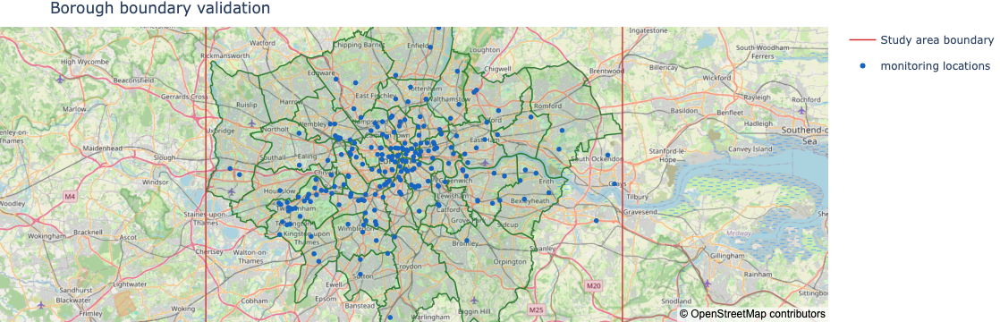

In [46]:
fig1 = go.Figure()
for _, row in boroughs_df.iterrows():
    if row["geometry_bng"] is None:
        continue
    inside = row["borough"] in set(BOROUGHS["borough"])
    geom_wgs = to_wgs84(row["geometry_bng"])
    fig1.add_traces(polygon_traces(geom_wgs, row["borough"],
                                   line_color="#2e7d32" if inside else "#9e9e9e",
                                   fill_color="rgba(46,125,50,0.12)" if inside else "rgba(158,158,158,0.10)",
                                   hover_text=row["borough"], legendgroup="in study" if inside else "outside study",
                                   showlegend=False))
fig1.add_traces(polygon_traces(STUDY_BOX_WGS84, "Study area boundary", line_color="#d32f2f", legendgroup="study box"))

hover_loc = loc_coords.apply(lambda r: f"{r['location_id']}<br>lat {r['latitude']:.4f}, lon {r['longitude']:.4f}<br>borough: {r['borough']}", axis=1)
fig1.add_trace(ScatterMapTrace(lat=loc_coords["latitude"], lon=loc_coords["longitude"], mode="markers",
                                marker=dict(size=6, color="#1565c0"), name="monitoring locations",
                                text=hover_loc, hoverinfo="text"))
fig1.update_layout(**{MAP_LAYOUT_KEY: dict(style=MAPBOX_STYLE, center=MAP_CENTER, zoom=8.6)}, height=650,
                   margin=dict(l=0, r=0, t=30, b=0), title="Borough boundary validation")
fig1.write_html(os.path.join(MAPS_DIR, "map1_borough_validation.html"))
fig1.show()

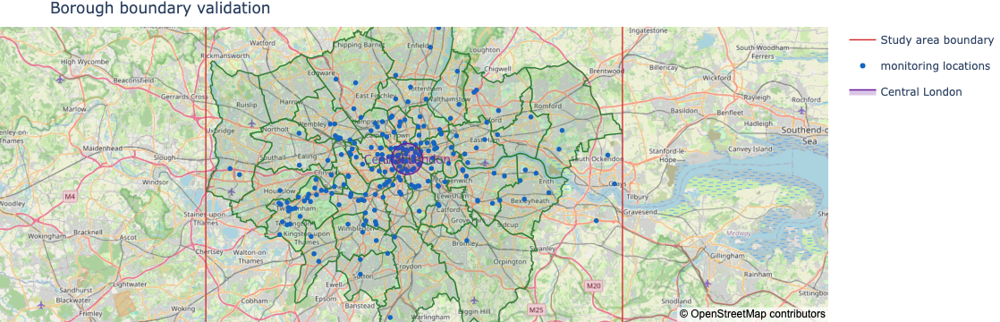

In [47]:
fig1.add_traces(polygon_traces(
    CENTRAL_LONDON_GEOM,
    "Central London",
    line_color="#6a1b9a",
    fill_color="rgba(106,27,154,0.25)",
    hover_text=f"Central London core ({CENTRAL_LONDON_RADIUS_M/1000:.1f} km radius)",
    legendgroup="central london",
))
fig1.add_trace(ScatterMapTrace(
    lat=[central_london_point.y], lon=[central_london_point.x],
    mode="text", text=["Central London"],
    textfont=dict(size=14, color="#6a1b9a"),
    hoverinfo="skip", showlegend=False,
))

In [48]:
import numpy as np

# Training sites: location + mean PM2.5 per sensor
train_locs = (
    train_df.groupby("sensor_id")
    .agg(latitude=("latitude", "first"), longitude=("longitude", "first"),
         pm25=("pm25", "mean"))
    .dropna(subset=["latitude", "longitude"])
    .reset_index()
)

def robust_limits(s, lo=2, hi=98):
    return float(np.nanpercentile(s, lo)), float(np.nanpercentile(s, hi))

print("training sensors:", len(train_locs))

training sensors: 218


In [49]:
import os

# Per-location means for observed, baseline and every scenario, plus coordinates
loc_level = tb.groupby("location_id")[
    ["observed", "baseline"]
    + [f"cf::{n}" for n in SCEN_NAMES]
    + [f"delta::{n}" for n in SCEN_NAMES]
].mean()

loc_level = loc_level.join(
    loc_coords.set_index("location_id")[["latitude", "longitude", "borough"]]
)
loc_level.to_csv(os.path.join(OUTPUT_DIR, "location_level_summary.csv"))

print("locations:", len(loc_level))

locations: 44


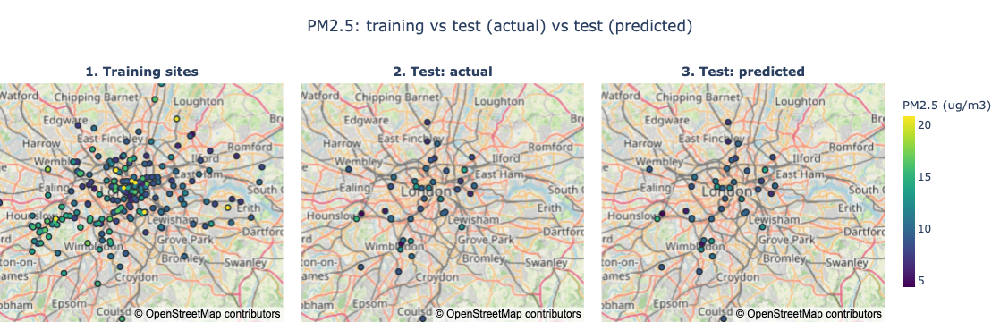

In [50]:
def three_panel_map(pred_col="baseline", obs_col="observed",
                    title="PM2.5: training vs test (actual) vs test (predicted)",
                    colorbar_title="PM2.5 (ug/m3)", colorscale="Viridis",
                    point_size=5, basemap=None, zoom=8.3):
    m = MAP_LAYOUT_KEY
    subplots = [m, f"{m}2", f"{m}3"]
    style = basemap or MAPBOX_STYLE

    # One shared, outlier-robust color range across all three panels
    all_vals = np.concatenate([
        train_locs["pm25"].to_numpy(),
        loc_level[obs_col].to_numpy(),
        loc_level[pred_col].to_numpy(),
    ])
    cmin, cmax = robust_limits(all_vals)

    RING = "#263238"
    fig = go.Figure()

    def add_layer(df, vals, hover, subplot, showscale=False):
        order = np.argsort(np.asarray(vals))          # high values drawn on top
        df, vals, hover = df.iloc[order], np.asarray(vals)[order], hover.iloc[order]
        # dark ring underneath
        fig.add_trace(ScatterMapTrace(
            lat=df["latitude"], lon=df["longitude"], mode="markers",
            marker=dict(size=point_size + 3, color=RING, opacity=1),
            hoverinfo="skip", showlegend=False, subplot=subplot))
        marker = dict(size=point_size, opacity=1, color=vals, colorscale=colorscale,
                      cmin=cmin, cmax=cmax, showscale=showscale)
        if showscale:
            marker["colorbar"] = dict(title=dict(text=colorbar_title, font=dict(size=13)),
                                      tickfont=dict(size=12), len=0.8, thickness=14, x=1.01)
        fig.add_trace(ScatterMapTrace(
            lat=df["latitude"], lon=df["longitude"], mode="markers",
            marker=marker, text=hover, hoverinfo="text",
            showlegend=False, subplot=subplot))

    # Training sites
    tr = train_locs.reset_index(drop=True)
    tr_hover = ("sensor " + tr["sensor_id"].astype(str)
                + "<br>mean PM2.5: " + tr["pm25"].round(2).astype(str))
    add_layer(tr, tr["pm25"], tr_hover, subplots[0])

    # Actual test values and predicted test values
    te = loc_level.reset_index().rename(columns={"index": "location_id"})
    id_col = te.columns[0]
    for col, sp, label, scale in [(obs_col, subplots[1], "actual", False),
                                  (pred_col, subplots[2], "predicted", True)]:
        hov = (te[id_col].astype(str) + "<br>borough: " + te["borough"].astype(str)
               + f"<br>{label}: " + te[col].round(2).astype(str))
        add_layer(te, te[col], hov, sp, showscale=scale)

    base = dict(style=style, center=MAP_CENTER, zoom=zoom)
    domains = [[0.00, 0.32], [0.34, 0.66], [0.68, 1.00]]
    titles = ["1. Training sites", "2. Test: actual", "3. Test: predicted"]

    fig.update_layout(
        **{sp: dict(base, domain=dict(x=d, y=[0, 0.92])) for sp, d in zip(subplots, domains)},
        height=480, margin=dict(l=0, r=90, t=70, b=0),
        title=dict(text=title, x=0.5, xanchor="center", font=dict(size=17)),
        annotations=[
            dict(text=f"<b>{t}</b>",
                 x=(d[0] + d[1]) / 2, xref="paper", xanchor="center",
                 y=0.93, yref="paper", yanchor="bottom",
                 showarrow=False, font=dict(size=14))
            for t, d in zip(titles, domains)
        ],
    )
    return fig


fig3 = three_panel_map()
fig3.write_html(os.path.join(MAPS_DIR, "map3_train_actual_predicted.html")); fig3.show()

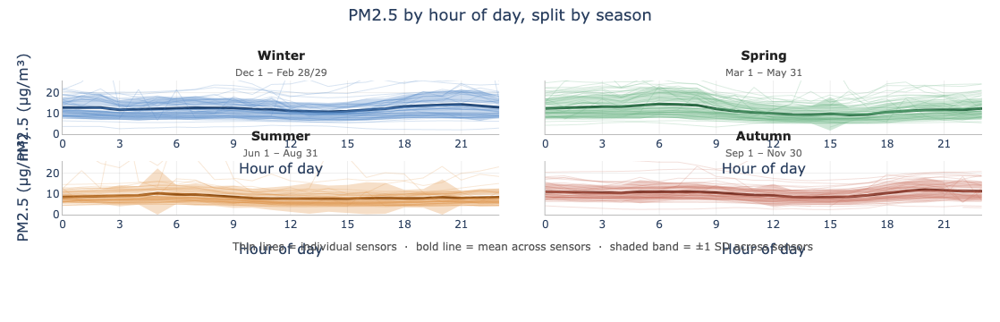

In [51]:
import os
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

SEASON_RANGE = {
    "Winter": "Dec 1 – Feb 28/29",
    "Spring": "Mar 1 – May 31",
    "Summer": "Jun 1 – Aug 31",
    "Autumn": "Sep 1 – Nov 30",
}
SEASON_OF_MONTH = {12: "Winter", 1: "Winter", 2: "Winter",
                   3: "Spring", 4: "Spring", 5: "Spring",
                   6: "Summer", 7: "Summer", 8: "Summer",
                   9: "Autumn", 10: "Autumn", 11: "Autumn"}
SEASONS = ["Winter", "Spring", "Summer", "Autumn"]
SEASON_START_MONTH = {"Winter": 12, "Spring": 3, "Summer": 6, "Autumn": 9}

# (base color for lines/band, darker shade for the mean)
SEASON_COLORS = {
    "Winter": ("#4f86c6", "#1d3f6b"),
    "Spring": ("#5fae7b", "#1f5a38"),
    "Summer": ("#e0954a", "#8a4a0f"),
    "Autumn": ("#c9705f", "#6e2a1f"),
}


def _rgba(hex_color, alpha):
    h = hex_color.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{alpha})"


def season_pm25_figure(df, mode="diurnal", tz="Europe/London",
                       sensor_alpha=0.22, band_alpha=0.30, max_sensors=60,
                       y_cap_percentile=98, smooth_days=7, height=820,
                       title="PM2.5 by season", seed=0):
    d = df[["datetime", "sensor_id", "pm25"]].dropna().copy()
    d["datetime"] = pd.to_datetime(d["datetime"], utc=True).dt.tz_convert(tz)
    d["season"] = d["datetime"].dt.month.map(SEASON_OF_MONTH)

    # Small panel headings: season name + date range + data actually present
    span = d.groupby("season")["datetime"].agg(["min", "max"])
    panel_titles = [
        f"<b>{s}</b><br><span style='font-size:11px;color:#666'>{SEASON_RANGE[s]}</span>"
        for s in SEASONS
    ]

    wides = {}
    if mode == "diurnal":
        d["x"] = d["datetime"].dt.hour
        prof = d.groupby(["season", "sensor_id", "x"])["pm25"].mean().reset_index()
        for s in SEASONS:
            wides[s] = (prof[prof["season"] == s]
                        .pivot(index="x", columns="sensor_id", values="pm25")
                        .reindex(range(24)))
        xtitle, xrange, xdtick = "Hour of day", [0, 23], 3
    else:
        local = d["datetime"].dt.tz_localize(None)
        d["date"] = local.dt.floor("D")
        start_year = np.where((d["season"] == "Winter") & (local.dt.month <= 2),
                              local.dt.year - 1, local.dt.year)
        season_start = pd.to_datetime(dict(year=start_year,
                                           month=d["season"].map(SEASON_START_MONTH), day=1))
        d["x"] = (d["date"] - season_start).dt.days
        daily = d.groupby(["season", "sensor_id", "date", "x"])["pm25"].mean().reset_index()
        clim = daily.groupby(["season", "sensor_id", "x"])["pm25"].mean().reset_index()
        for s in SEASONS:
            w = (clim[clim["season"] == s]
                 .pivot(index="x", columns="sensor_id", values="pm25")
                 .reindex(range(0, 92)))
            wides[s] = w.rolling(smooth_days, center=True, min_periods=1).mean()
        xtitle, xrange, xdtick = "Day of season", [0, 91], 15

    # Shared y-limit (from mean ± SD so the band is never clipped)
    tops = [(w.mean(axis=1) + w.std(axis=1)).max() for w in wides.values()]
    sensor_top = np.nanpercentile(
        np.concatenate([w.to_numpy().ravel() for w in wides.values()]), y_cap_percentile)
    y_max = float(max(max(tops), sensor_top)) * 1.05

    rng = np.random.default_rng(seed)
    fig = make_subplots(rows=2, cols=2, subplot_titles=panel_titles,
                        shared_xaxes=False, shared_yaxes=True,
                        horizontal_spacing=0.05, vertical_spacing=0.20)

    for i, s in enumerate(SEASONS):
        row, col = i // 2 + 1, i % 2 + 1
        w = wides[s]
        base, dark = SEASON_COLORS[s]
        mean, sd = w.mean(axis=1), w.std(axis=1)

        # SD band
        fig.add_trace(go.Scatter(x=w.index, y=mean + sd, mode="lines", line=dict(width=0),
                                 hoverinfo="skip", showlegend=False), row=row, col=col)
        fig.add_trace(go.Scatter(x=w.index, y=(mean - sd).clip(lower=0), mode="lines",
                                 line=dict(width=0), fill="tonexty",
                                 fillcolor=_rgba(base, band_alpha),
                                 hoverinfo="skip", showlegend=False), row=row, col=col)

        # Individual sensors
        cols = list(w.columns)
        if max_sensors and len(cols) > max_sensors:
            cols = list(rng.choice(cols, max_sensors, replace=False))
        for sid in cols:
            fig.add_trace(go.Scattergl(x=w.index, y=w[sid], mode="lines",
                                       line=dict(width=1, color=_rgba(base, sensor_alpha)),
                                       hovertemplate=f"sensor {sid}: %{{y:.1f}}<extra></extra>",
                                       showlegend=False), row=row, col=col)

        # Mean with white outline
        fig.add_trace(go.Scatter(x=w.index, y=mean, mode="lines",
                                 line=dict(width=6, color="white"),
                                 hoverinfo="skip", showlegend=False), row=row, col=col)
        fig.add_trace(go.Scatter(x=w.index, y=mean, mode="lines",
                                 line=dict(width=3, color=dark),
                                 hovertemplate="mean: %{y:.1f}<extra></extra>",
                                 showlegend=False), row=row, col=col)

    grid = "rgba(0,0,0,0.07)"
    fig.update_xaxes(showgrid=True, gridcolor=grid, zeroline=False, range=xrange,
                     dtick=xdtick, showticklabels=True, title_text=xtitle,
                     tickfont=dict(size=12), linecolor="#bbb")
    fig.update_yaxes(showgrid=True, gridcolor=grid, zeroline=False, range=[0, y_max],
                     tickfont=dict(size=12), linecolor="#bbb")
    fig.update_yaxes(title_text="PM2.5 (µg/m³)", col=1)
    fig.update_annotations(font=dict(size=14, color="#222"))   # panel titles only (key added below)

    # Key at the bottom so it can't collide with panel titles
    fig.add_annotation(
        text="Thin lines = individual sensors  ·  bold line = mean across sensors  ·  shaded band = ±1 SD across sensors",
        xref="paper", yref="paper", x=0.5, y=-0.17, xanchor="center", yanchor="top",
        showarrow=False, font=dict(size=12, color="#555"))

    fig.update_layout(
        title=dict(text=title, x=0.5, xanchor="center", y=0.97, yanchor="top",
                   font=dict(size=18)),
        height=height, plot_bgcolor="white", paper_bgcolor="white",
        font=dict(size=13), margin=dict(l=70, r=20, t=90, b=120))
    return fig


fig_season = season_pm25_figure(train_df, mode="diurnal",
                                title="PM2.5 by hour of day, split by season")
fig_season.write_html(os.path.join(MAPS_DIR, "pm25_by_season_diurnal.html"))
fig_season.show()

In [52]:
def _geom_outline_lonlat(geom):
    """Return lon/lat lists for a (Multi)Polygon outline, with None gaps between rings."""
    polys = list(geom.geoms) if hasattr(geom, "geoms") else [geom]
    lons, lats = [], []
    for p in polys:
        x, y = p.exterior.xy
        lons += list(x) + [None]
        lats += list(y) + [None]
    return lons, lats

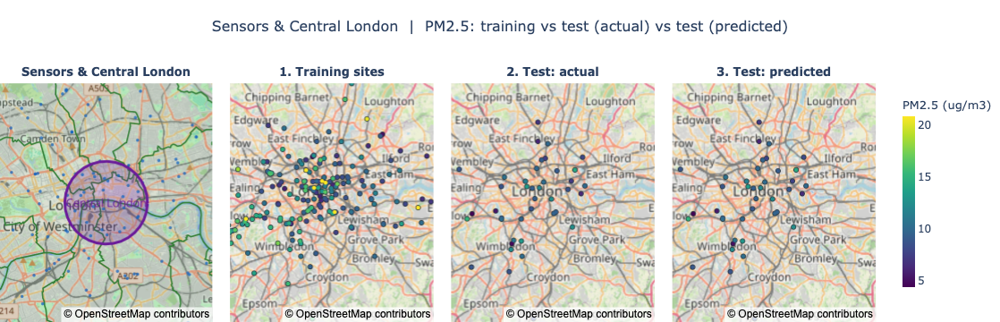

In [53]:
def four_panel_map(pred_col="baseline", obs_col="observed",
                   colorscale="Viridis", point_size=5, ring_extra=1.5,
                   basemap=None, zoom_pm=8.3, zoom_central=10,
                   sensor_size_overview=4,          # dots in the first panel
                   title="Sensors & Central London  |  PM2.5: training vs test (actual) vs test (predicted)"):
    m = MAP_LAYOUT_KEY
    sp = [m, f"{m}2", f"{m}3", f"{m}4"]
    style = basemap or MAPBOX_STYLE
    fig = go.Figure()

    # Panel 0: borough validation map, zoomed on Central London
    def put(traces, subplot):
        for t in traces:
            t.subplot = subplot
            t.showlegend = False
        fig.add_traces(traces)

    for _, row in boroughs_df.iterrows():
        if row["geometry_bng"] is None:
            continue
        inside = row["borough"] in set(BOROUGHS["borough"])
        put(list(polygon_traces(
            to_wgs84(row["geometry_bng"]), row["borough"],
            line_color="#2e7d32" if inside else "#9e9e9e",
            fill_color="rgba(46,125,50,0.12)" if inside else "rgba(158,158,158,0.10)",
            hover_text=row["borough"],
            legendgroup="in study" if inside else "outside study",
            showlegend=False)), sp[0])

    put(list(polygon_traces(STUDY_BOX_WGS84, "Study area boundary",
                            line_color="#d32f2f", legendgroup="study box")), sp[0])
    put(list(polygon_traces(
        CENTRAL_LONDON_GEOM, "Central London",
        line_color="#6a1b9a", fill_color="rgba(106,27,154,0.25)",
        hover_text=f"Central London core ({CENTRAL_LONDON_RADIUS_M/1000:.1f} km radius)",
        legendgroup="central london")), sp[0])

    hover_loc = loc_coords.apply(
        lambda r: f"{r['location_id']}<br>lat {r['latitude']:.4f}, lon {r['longitude']:.4f}"
                  f"<br>borough: {r['borough']}", axis=1)
        # Small, slightly transparent sensor dots so the circle shows through
    fig.add_trace(ScatterMapTrace(
        lat=loc_coords["latitude"], lon=loc_coords["longitude"], mode="markers",
        marker=dict(size=sensor_size_overview, color="#1565c0", opacity=0.75),
        text=hover_loc, hoverinfo="text",
        showlegend=False, subplot=sp[0]))

    # Central London outline drawn after the dots, so it sits on top and stays visible
    _lons, _lats = _geom_outline_lonlat(CENTRAL_LONDON_GEOM)
    fig.add_trace(ScatterMapTrace(
        lon=_lons, lat=_lats, mode="lines",
        line=dict(width=3, color="#6a1b9a"),
        hoverinfo="skip", showlegend=False, subplot=sp[0]))

    fig.add_trace(ScatterMapTrace(
        lat=[central_london_point.y], lon=[central_london_point.x],
        mode="text", text=["Central London"],
        textfont=dict(size=13, color="#6a1b9a"),
        hoverinfo="skip", showlegend=False, subplot=sp[0]))

    # Panels 1-3: training / actual / predicted (as before)
    all_vals = np.concatenate([train_locs["pm25"].to_numpy(),
                               loc_level[obs_col].to_numpy(),
                               loc_level[pred_col].to_numpy()])
    cmin, cmax = robust_limits(all_vals)
    RING = "#263238"

    def add_layer(df, vals, hover, subplot, showscale=False):
        order = np.argsort(np.asarray(vals))
        df, vals, hover = df.iloc[order], np.asarray(vals)[order], hover.iloc[order]
        fig.add_trace(ScatterMapTrace(
            lat=df["latitude"], lon=df["longitude"], mode="markers",
            marker=dict(size=point_size + ring_extra, color=RING, opacity=1),
            hoverinfo="skip", showlegend=False, subplot=subplot))
        marker = dict(size=point_size, opacity=1, color=vals, colorscale=colorscale,
                      cmin=cmin, cmax=cmax, showscale=showscale)
        if showscale:
            marker["colorbar"] = dict(title=dict(text="PM2.5 (ug/m3)", font=dict(size=13)),
                                      tickfont=dict(size=12), len=0.8, thickness=14, x=1.01)
        fig.add_trace(ScatterMapTrace(
            lat=df["latitude"], lon=df["longitude"], mode="markers",
            marker=marker, text=hover, hoverinfo="text",
            showlegend=False, subplot=subplot))

    tr = train_locs.reset_index(drop=True)
    tr_hover = ("sensor " + tr["sensor_id"].astype(str)
                + "<br>mean PM2.5: " + tr["pm25"].round(2).astype(str))
    add_layer(tr, tr["pm25"], tr_hover, sp[1])

    te = loc_level.reset_index().rename(columns={"index": "location_id"})
    id_col = te.columns[0]
    for col, s, label, scale in [(obs_col, sp[2], "actual", False),
                                 (pred_col, sp[3], "predicted", True)]:
        hov = (te[id_col].astype(str) + "<br>borough: " + te["borough"].astype(str)
               + f"<br>{label}: " + te[col].round(2).astype(str))
        add_layer(te, te[col], hov, s, showscale=scale)

    # Layout
    c = CENTRAL_LONDON_GEOM.centroid
    domains = [[0.00, 0.24], [0.26, 0.49], [0.51, 0.74], [0.76, 0.99]]
    views = [dict(style=style, center=dict(lat=c.y, lon=c.x), zoom=zoom_central)] + \
            [dict(style=style, center=MAP_CENTER, zoom=zoom_pm)] * 3
    heads = ["Sensors & Central London", "1. Training sites",
             "2. Test: actual", "3. Test: predicted"]

    fig.update_layout(
        **{s: dict(v, domain=dict(x=d, y=[0, 0.92])) for s, v, d in zip(sp, views, domains)},
        height=520, margin=dict(l=0, r=90, t=70, b=0),
        title=dict(text=title, x=0.5, xanchor="center", font=dict(size=16)),
        annotations=[
            dict(text=f"<b>{t}</b>", x=(d[0] + d[1]) / 2, xref="paper", xanchor="center",
                 y=0.93, yref="paper", yanchor="bottom", showarrow=False, font=dict(size=13))
            for t, d in zip(heads, domains)
        ],
    )
    return fig


fig4 = four_panel_map()
fig4.write_html(os.path.join(MAPS_DIR, "map4_sensors_train_actual_predicted.html"))
fig4.show()

Central London: 3 locations inside the circle
nearest_traffic_aadf                       CL change -0.012 to +0.000  | color range ±0.018
road_length_250m                           CL change -0.019 to +0.016  | color range ±0.018
major_road_length_250m                     CL change -0.121 to +0.012  | color range ±0.025
ndvi                                       CL change -0.008 to +0.012  | color range ±0.043
landcover_2020_group_Built-up              CL change -0.001 to +0.000  | color range ±0.001
landcover_2020_group_Green/open space      CL change -0.000 to +0.000  | color range ±0.001
landcover_2020_group_Tree cover            CL change -0.001 to +0.001  | color range ±0.001


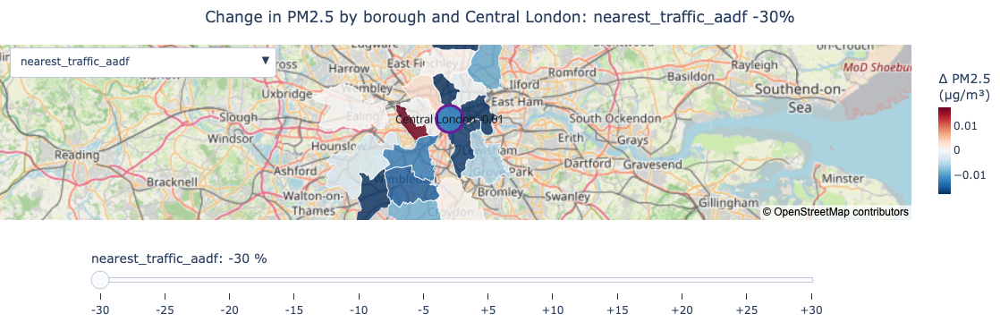

,scenario,baseline,counterfactual,change,change_%
0,nearest_traffic_aadf -5%,11.565533,11.565857,0.000324,0.002804
1,nearest_traffic_aadf -10%,11.565533,11.560806,-0.004727,-0.040869
2,nearest_traffic_aadf -15%,11.565533,11.560551,-0.004982,-0.043076
3,nearest_traffic_aadf -20%,11.565533,11.558177,-0.007357,-0.063607
4,nearest_traffic_aadf -25%,11.565533,11.558078,-0.007455,-0.064456
...,...,...,...,...,...
79,landcover_2020_group_Tree cover +10%,11.565533,11.565619,0.000086,0.000747
80,landcover_2020_group_Tree cover +15%,11.565533,11.565488,-0.000045,-0.000390
81,landcover_2020_group_Tree cover +20%,11.565533,11.565869,0.000336,0.002904
82,landcover_2020_group_Tree cover +25%,11.565533,11.566050,0.000517,0.004467


In [54]:
import os
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.colors import sample_colorscale
from shapely.geometry import Point

geojson = borough_geojson(BOROUGHS)

RANGE_PCT = 90          # color range = this percentile of |change| (lower = stronger colors)
COLORSCALE = "RdBu_r"

LEVER_LABEL = {"ndvi_v3_final": "ndvi"}
def lever_label(lever):
    return LEVER_LABEL.get(lever, lever)

# Borough means
delta_cols = [f"delta::{n}" for n in SCEN_NAMES]
cf_cols    = [f"cf::{n}" for n in SCEN_NAMES]
stat_cols  = ["baseline"] + delta_cols + cf_cols

loc_mean = tb.groupby(["location_id", "borough"])[stat_cols].mean().reset_index()
bor = loc_mean.groupby("borough")[stat_cols].mean()

# Central London
cl_geom = CENTRAL_LONDON_GEOM
cl_point = cl_geom.representative_point()

pts = loc_coords[["location_id", "latitude", "longitude"]].drop_duplicates("location_id")
in_circle_ids = pts.loc[
    [cl_geom.contains(Point(lon, lat)) for lon, lat in zip(pts["longitude"], pts["latitude"])],
    "location_id"
]
cl_loc = loc_mean[loc_mean["location_id"].isin(in_circle_ids)]
assert len(cl_loc) > 0, "No test locations fall inside the Central London circle."
cl = cl_loc[stat_cols].mean()
cl_n = cl_loc["location_id"].nunique()
print(f"Central London: {cl_n} locations inside the circle")

_ring = cl_geom.exterior if hasattr(cl_geom, "exterior") else cl_geom.geoms[0].exterior
CL_LON, CL_LAT = [list(c) for c in _ring.xy]

# Slider positions
SIGNED = [-p for p in sorted(PCTS, reverse=True)] + sorted(PCTS)

def scen(lever, signed):
    return scenario_name(lever, "decrease" if signed < 0 else "increase", abs(signed))

def scen_label(lever, signed):
    return scen(lever, signed).replace(lever, lever_label(lever), 1)

# Per-lever symmetric color range (robust: percentile, not max)
def lever_range(lever):
    cols = [f"delta::{scen(lever, s)}" for s in SIGNED]
    vals = np.abs(np.concatenate([bor[cols].to_numpy().ravel(), cl[cols].to_numpy().ravel()]))
    mm = float(np.nanpercentile(vals, RANGE_PCT))
    return mm if mm > 0 else 1e-6

LEVER_M = {lever: lever_range(lever) for lever in LEVERS}

for lever in LEVERS:
    cols = [f"delta::{scen(lever, s)}" for s in SIGNED]
    print(f"{lever_label(lever):<42} CL change {cl[cols].min():+.3f} to {cl[cols].max():+.3f}"
          f"  | color range ±{LEVER_M[lever]:.3f}")

def cl_color(value, mm, alpha=0.95):
    frac = float(np.clip(0.5 + value / (2 * mm), 0, 1))
    rgb = sample_colorscale(COLORSCALE, [frac])[0]
    if rgb.startswith("#"):
        h = rgb.lstrip("#")
        r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
        return f"rgba({r},{g},{b},{alpha})"
    return rgb.replace("rgb(", "rgba(").replace(")", f", {alpha})")

# Traces: boroughs, Central London fill, Central London label
fig = go.Figure()
trace_index = {}
for lever in LEVERS:
    for s in SIGNED:
        n = scen(lever, s)
        n_show = scen_label(lever, s)
        d = bor[f"delta::{n}"]
        hover = [
            f"<b>{b}</b><br>{n_show}"
            f"<br>change: {d.loc[b]:+.3f} µg/m³"
            f"<br>baseline: {bor.loc[b, 'baseline']:.2f}"
            f"<br>counterfactual: {bor.loc[b, f'cf::{n}']:.2f}"
            for b in d.index
        ]
        idx = []

        idx.append(len(fig.data))
        fig.add_trace(ChoroplethMapTrace(
            geojson=geojson, locations=d.index, z=d.values,
            featureidkey="properties.borough", coloraxis="coloraxis",
            marker_opacity=0.8, marker_line_width=1, marker_line_color="white",
            text=hover, hoverinfo="text", visible=False))

        cl_d = float(cl[f"delta::{n}"])
        cl_hover = (f"<b>Central London</b> ({cl_n} locations)<br>{n_show}"
                    f"<br>change: {cl_d:+.3f} µg/m³"
                    f"<br>baseline: {cl['baseline']:.2f}"
                    f"<br>counterfactual: {cl[f'cf::{n}']:.2f}")
        idx.append(len(fig.data))
        fig.add_trace(ScatterMapTrace(
            lon=CL_LON, lat=CL_LAT, mode="lines", fill="toself",
            fillcolor=cl_color(cl_d, LEVER_M[lever]),
            line=dict(width=3, color="#6a1b9a"),
            hoverinfo="skip", showlegend=False, visible=False))

        # Plain text only: map labels do not render HTML
        idx.append(len(fig.data))
        fig.add_trace(ScatterMapTrace(
            lat=[cl_point.y], lon=[cl_point.x], mode="text",
            text=[f"Central London {cl_d:+.2f}"],
            textfont=dict(size=13, color="#111"),
            hovertext=[cl_hover], hoverinfo="text",
            showlegend=False, visible=False))

        trace_index[(lever, s)] = idx

n_traces = len(fig.data)

def visible_for(lever, s):
    vis = [False] * n_traces
    for i in trace_index[(lever, s)]:
        vis[i] = True
    return vis

def title_for(lever, s):
    return f"Change in PM2.5 by borough and Central London: {scen_label(lever, s)}"

def layout_update(lever, s, include_slider=False):
    mm = LEVER_M[lever]
    upd = {"title.text": title_for(lever, s),
           "coloraxis.cmin": -mm, "coloraxis.cmax": mm}
    if include_slider:
        upd["sliders"] = [slider_for(lever)]
    return upd

def slider_for(lever):
    return dict(
        active=0, x=0.1, len=0.8, y=0, yanchor="top", pad=dict(t=30, b=10),
        currentvalue=dict(prefix=f"{lever_label(lever)}: ", suffix=" %", font=dict(size=14)),
        steps=[dict(method="update", label=f"{s:+d}",
                    args=[{"visible": visible_for(lever, s)}, layout_update(lever, s)])
               for s in SIGNED])

buttons = [dict(label=lever_label(lever), method="update",
                args=[{"visible": visible_for(lever, SIGNED[0])},
                      layout_update(lever, SIGNED[0], include_slider=True)])
           for lever in LEVERS]

for i in trace_index[(LEVERS[0], SIGNED[0])]:
    fig.data[i].visible = True

m0 = LEVER_M[LEVERS[0]]
fig.update_layout(
    **{MAP_LAYOUT_KEY: dict(style=MAPBOX_STYLE, center=MAP_CENTER, zoom=8.4)},
    coloraxis=dict(colorscale=COLORSCALE, cmin=-m0, cmax=m0, cmid=0,
                   colorbar=dict(title="Δ PM2.5<br>(µg/m³)", thickness=14, len=0.8)),
    sliders=[slider_for(LEVERS[0])],
    updatemenus=[dict(type="dropdown", buttons=buttons, x=0.01, y=0.99,
                      xanchor="left", yanchor="top", bgcolor="white")],
    title=dict(text=title_for(LEVERS[0], SIGNED[0]), x=0.5, xanchor="center"),
    height=700, margin=dict(l=0, r=0, t=50, b=90),
)

fig.write_html(os.path.join(MAPS_DIR, "map7_counterfactual_slider_central.html"))
fig.show()

# Table of Central London's change
cl_table = pd.DataFrame({
    "scenario": [n.replace("ndvi_v3_final", "ndvi") for n in SCEN_NAMES],
    "baseline": float(cl["baseline"]),
    "counterfactual": [float(cl[f"cf::{n}"]) for n in SCEN_NAMES],
    "change": [float(cl[f"delta::{n}"]) for n in SCEN_NAMES],
})
cl_table["change_%"] = 100 * cl_table["change"] / cl_table["baseline"]
cl_table.to_csv(os.path.join(OUTPUT_DIR, "central_london_scenario_changes.csv"), index=False)
display(cl_table)

Best lookback per model: {'ElasticNet': 1, 'Random Forest': 14, 'LightGBM': 9, 'XGBoost': 3, 'CatBoost': 6, 'MLP': 15, 'PyTorch RNN': 15}


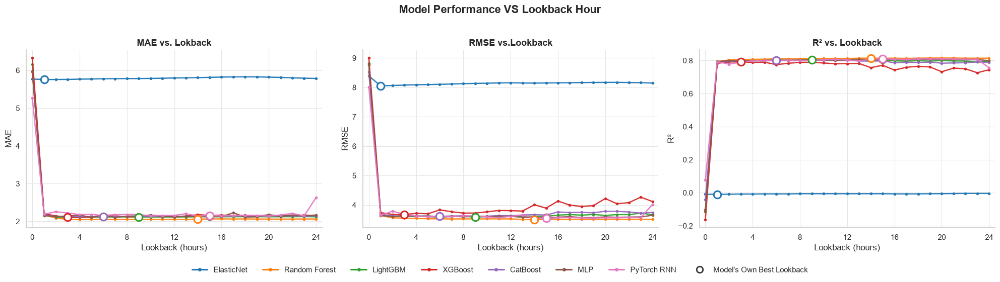

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Data (lookback = 0..24 hours, one list per model)
lookbacks = list(range(25))

data = {
    "ElasticNet": {
        "MAE":  [5.770,5.756,5.758,5.760,5.766,5.771,5.776,5.779,5.781,5.783,5.786,5.791,5.797,5.801,5.807,5.814,5.821,5.826,5.828,5.826,5.820,5.813,5.801,5.792,5.785],
        "RMSE": [8.388,8.054,8.065,8.077,8.090,8.095,8.105,8.115,8.127,8.136,8.143,8.152,8.158,8.149,8.146,8.152,8.155,8.160,8.164,8.168,8.170,8.171,8.166,8.161,8.147],
        "R2":   [-0.009,-0.010,-0.009,-0.008,-0.008,-0.007,-0.007,-0.007,-0.006,-0.006,-0.006,-0.006,-0.006,-0.006,-0.006,-0.006,-0.007,-0.007,-0.007,-0.006,-0.006,-0.005,-0.004,-0.004,-0.004],
    },
    "Random Forest": {
        "MAE":  [5.953,2.170,2.086,2.051,2.049,2.051,2.051,2.051,2.052,2.051,2.053,2.054,2.054,2.054,2.058,2.063,2.065,2.062,2.064,2.061,2.060,2.058,2.060,2.062,2.061],
        "RMSE": [8.769,3.637,3.561,3.547,3.540,3.530,3.524,3.522,3.523,3.523,3.524,3.524,3.523,3.505,3.503,3.505,3.509,3.513,3.508,3.506,3.508,3.510,3.512,3.511,3.507],
        "R2":   [-0.103,0.794,0.803,0.806,0.807,0.808,0.810,0.810,0.811,0.811,0.812,0.812,0.812,0.814,0.814,0.814,0.814,0.813,0.814,0.815,0.815,0.815,0.814,0.814,0.814],
    },
    "LightGBM": {
        "MAE":  [6.159,2.165,2.117,2.102,2.107,2.110,2.115,2.117,2.118,2.117,2.115,2.116,2.117,2.117,2.120,2.121,2.121,2.123,2.124,2.124,2.120,2.122,2.123,2.125,2.121],
        "RMSE": [8.811,3.678,3.607,3.606,3.610,3.625,3.599,3.600,3.613,3.581,3.604,3.588,3.612,3.612,3.615,3.612,3.651,3.671,3.651,3.674,3.642,3.670,3.669,3.719,3.667],
        "R2":   [-0.114,0.790,0.798,0.799,0.799,0.798,0.801,0.802,0.801,0.805,0.803,0.805,0.803,0.802,0.802,0.802,0.798,0.796,0.799,0.796,0.800,0.797,0.797,0.792,0.797],
    },
    "XGBoost": {
        "MAE":  [6.326,2.202,2.143,2.109,2.107,2.116,2.139,2.145,2.123,2.117,2.142,2.130,2.130,2.139,2.177,2.157,2.164,2.157,2.161,2.146,2.165,2.148,2.151,2.166,2.154],
        "RMSE": [9.000,3.738,3.675,3.670,3.713,3.697,3.831,3.768,3.721,3.722,3.766,3.810,3.803,3.791,4.002,3.890,4.131,3.993,3.946,3.976,4.215,4.039,4.077,4.264,4.115],
        "R2":   [-0.162,0.783,0.791,0.792,0.788,0.790,0.775,0.783,0.789,0.789,0.785,0.780,0.781,0.782,0.757,0.771,0.742,0.759,0.765,0.761,0.732,0.754,0.750,0.726,0.744],
    },
    "CatBoost": {
        "MAE":  [5.971,2.169,2.130,2.128,2.124,2.126,2.127,2.130,2.132,2.130,2.137,2.132,2.129,2.136,2.137,2.135,2.143,2.145,2.144,2.141,2.143,2.147,2.146,2.142,2.145],
        "RMSE": [8.521,3.682,3.626,3.623,3.628,3.613,3.610,3.621,3.629,3.615,3.614,3.637,3.631,3.657,3.667,3.654,3.760,3.740,3.746,3.732,3.783,3.780,3.758,3.719,3.745],
        "R2":   [-0.042,0.789,0.796,0.797,0.797,0.799,0.800,0.800,0.799,0.801,0.802,0.800,0.801,0.797,0.796,0.798,0.786,0.789,0.788,0.790,0.784,0.785,0.787,0.791,0.788],
    },
    "MLP": {
        "MAE":  [5.970,2.148,2.132,2.137,2.164,2.108,2.176,2.104,2.140,2.143,2.168,2.138,2.114,2.137,2.119,2.142,2.122,2.229,2.112,2.121,2.178,2.135,2.169,2.150,2.167],
        "RMSE": [8.778,3.639,3.601,3.640,3.617,3.601,3.581,3.610,3.595,3.611,3.599,3.616,3.611,3.577,3.574,3.566,3.582,3.599,3.569,3.567,3.591,3.577,3.585,3.591,3.647],
        "R2":   [-0.106,0.794,0.799,0.795,0.799,0.801,0.803,0.801,0.803,0.802,0.804,0.802,0.803,0.806,0.806,0.807,0.806,0.804,0.808,0.808,0.806,0.807,0.806,0.806,0.799],
    },
    "PyTorch RNN": {
        "MAE":  [5.266,2.190,2.255,2.220,2.179,2.183,2.157,2.176,2.184,2.182,2.143,2.157,2.157,2.202,2.140,2.155,2.143,2.150,2.157,2.155,2.140,2.168,2.209,2.147,2.626],
        "RMSE": [8.016,3.647,3.785,3.682,3.625,3.594,3.608,3.595,3.626,3.619,3.591,3.571,3.608,3.649,3.560,3.544,3.560,3.574,3.557,3.553,3.560,3.560,3.576,3.565,4.018],
        "R2":   [0.078,0.793,0.778,0.790,0.798,0.801,0.800,0.802,0.800,0.801,0.804,0.807,0.803,0.798,0.808,0.810,0.808,0.807,0.809,0.810,0.809,0.809,0.807,0.808,0.756],
    },
}

df = pd.DataFrame([
    {"lookback": L, "model": m, "MAE": d["MAE"][i], "RMSE": d["RMSE"][i], "R2": d["R2"][i]}
    for m, d in data.items() for i, L in enumerate(lookbacks)
])

models = list(data.keys())
colors = {m: plt.get_cmap("tab10")(i) for i, m in enumerate(models)}

# Each model's own best lookback = lowest RMSE
best_L_of = {m: int(df[df["model"] == m].loc[lambda s: s["RMSE"].idxmin(), "lookback"])
             for m in models}
print("Best lookback per model:", best_L_of)

# Plot
ZOOM = False   # zoom y-axis on the competitive models (excludes ElasticNet and lookback 0)
metrics = [("MAE",  "MAE vs. Lokback"),
           ("RMSE", "RMSE vs.Lookback"),
           ("R2",   "R² vs. Lookback")]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.6), sharex=True)

for ax, (metric, title) in zip(axes, metrics):
    for m in models:
        sub = df[df["model"] == m].sort_values("lookback")
        c = colors[m]
        ax.plot(sub["lookback"], sub[metric], color=c, lw=1.8, marker="o", ms=3, alpha=0.95)
        L = best_L_of[m]
        v = sub.loc[sub["lookback"] == L, metric].iloc[0]
        ax.scatter([L], [v], s=110, facecolors="white", edgecolors=c, linewidths=2.2, zorder=5)

    if ZOOM:
        core = df[(df["model"] != "ElasticNet") & (df["lookback"] >= 1)][metric]
        pad = 0.08 * (core.max() - core.min())
        ax.set_ylim(core.min() - pad, core.max() + pad)
        ax.text(0.99, 0.02, "Off-scale: ElasticNet and lookback 0",
                transform=ax.transAxes, ha="right", va="bottom",
                fontsize=9, color="0.4", style="italic")

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Lookback (hours)")
    ax.set_ylabel("R²" if metric == "R2" else metric)
    ax.set_xticks(range(0, 25, 4))
    ax.set_xlim(-0.5, 24.5)
    ax.grid(True, color="0.9", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

handles = [Line2D([0], [0], color=colors[m], lw=2.2, marker="o", ms=4, label=m) for m in models]
handles.append(Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                      markeredgecolor="0.2", markeredgewidth=2, ms=9,
                      label="Model's Own Best Lookback"))
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
           fontsize=11, bbox_to_anchor=(0.5, 0.0))

fig.suptitle("Model Performance VS Lookback Hour", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0.07, 1, 0.96))
plt.show()

In [58]:
print("Original baseline_predictions mean:",
      baseline_predictions.mean())

print("\nCSV baseline values:")
print(dose["baseline"].describe())

print("\nCSV counterfactual values:")
print(dose["counterfactual"].describe())

print("\nCSV scenarios:")
print(dose[["scenario", "baseline", "counterfactual",
            "change", "change_%"]].head(10))

Original baseline_predictions mean: 9.341616668075217

CSV baseline values:
count    4.800000e+01
mean     1.156553e+01
std      5.385464e-15
min      1.156553e+01
25%      1.156553e+01
50%      1.156553e+01
75%      1.156553e+01
max      1.156553e+01
Name: baseline, dtype: float64

CSV counterfactual values:
count    48.000000
mean     11.554068
std       0.030120
min      11.444102
25%      11.557316
50%      11.560889
75%      11.568489
max      11.581393
Name: counterfactual, dtype: float64

CSV scenarios:
                    scenario   baseline  counterfactual    change  change_%
0   nearest_traffic_aadf -5%  11.565533       11.565857  0.000324  0.002804
1  nearest_traffic_aadf -10%  11.565533       11.560806 -0.004727 -0.040869
2  nearest_traffic_aadf -15%  11.565533       11.560551 -0.004982 -0.043076
3  nearest_traffic_aadf -20%  11.565533       11.558177 -0.007357 -0.063607
4  nearest_traffic_aadf -25%  11.565533       11.558078 -0.007455 -0.064456
5  nearest_traffic_aadf -30%

In [59]:
print("Baseline predictions:")
print("Shape:", baseline_predictions.shape)
print("Mean:", baseline_predictions.mean())
print("Min:", baseline_predictions.min())
print("Max:", baseline_predictions.max())

print("\nCSV baseline:")
print(dose["baseline"].iloc[0])

print("\nCSV scenario count:", len(dose))
print("Unique features:", dose["Feature"].unique())

Baseline predictions:
Shape: (165369,)
Mean: 9.341616668075217
Min: 0.06212241727825302
Max: 56.05839034539657

CSV baseline:
11.565533085786903

CSV scenario count: 48
Unique features: <ArrowStringArray>
['nearest_traffic_aadf', 'road_length_250m', 'major_road_length_250m', 'ndvi']
Length: 4, dtype: str


In [60]:
borough_df = pd.read_csv("counterfactual_outputs/borough_by_hour.csv")

# View the first 5 rows
print(borough_df.head())

  borough  hour    n   observed   baseline  cf::nearest_traffic_aadf -5%  \
0  Camden     0  284  10.927437  12.284804                     12.284992   
1  Camden     1  285   8.480628  10.724349                     10.726214   
2  Camden     2  287   8.447500   8.834268                      8.834834   
3  Camden     3  288   8.351679   8.909531                      8.909830   
4  Camden     4  284   8.362742   8.750232                      8.750673   

   cf::nearest_traffic_aadf -10%  cf::nearest_traffic_aadf -15%  \
0                      12.284453                      12.283908   
1                      10.727743                      10.729018   
2                       8.834783                       8.834353   
3                       8.910595                       8.910027   
4                       8.751161                       8.751529   

   cf::nearest_traffic_aadf -20%  cf::nearest_traffic_aadf -25%  ...  \
0                      12.284574                      12.285503  ...

In [61]:
print(borough_df["borough"].unique())

<ArrowStringArray>
[              'Camden',              'Croydon',               'Ealing',
              'Enfield',              'Hackney',             'Haringey',
            'Islington', 'Kensington & Chelsea',             'Kingston',
             'Lewisham',               'Merton',             'Richmond',
            'Southwark',               'Sutton',        'Tower Hamlets',
       'Waltham Forest',           'Wandsworth',          'Westminster']
Length: 18, dtype: str


In [62]:
import os
import re
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# Load Central London data
central_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "central_london_scenario_changes.csv")
)

# Borough-level summary

borough_baseline = np.average(
    borough_df["baseline"],
    weights=borough_df["n"]
)

borough_rows = []

for col in borough_df.columns:
    if not col.startswith("delta::"):
        continue

    match = re.search(r"([+-]\d+(?:\.\d+)?)%$", col)

    if not match:
        continue

    signed_pct = float(match.group(1))
    feature = col[len("delta::"):]
    feature = re.sub(r"\s[+-]\d+(?:\.\d+)?%$", "", feature)

    valid = borough_df[col].notna() & borough_df["n"].notna()

    mean_change = np.average(
        borough_df.loc[valid, col],
        weights=borough_df.loc[valid, "n"]
    )

    borough_rows.append({
        "Feature": feature,
        "signed_pct": signed_pct,
        "change": mean_change,
        "change_%": mean_change / borough_baseline * 100,
        "baseline": borough_baseline
    })

borough_summary = pd.DataFrame(borough_rows)


# Central London summary

central_df["signed_pct"] = (
    central_df["scenario"]
    .str.extract(r"([+-]\d+(?:\.\d+)?)%$")
    .astype(float)
)

central_df["Feature"] = (
    central_df["scenario"]
    .str.replace(r"\s[+-]\d+(?:\.\d+)?%$", "", regex=True)
)

central_summary = central_df.rename(columns={
    "change": "change",
    "change_%": "change_%",
    "baseline": "baseline"
})

# Exclude landcover features from both datasets
borough_summary = borough_summary[
    ~borough_summary["Feature"].str.startswith("landcover_", na=False)
].copy()

central_summary = central_summary[
    ~central_summary["Feature"].str.startswith("landcover_", na=False)
].copy()

# Check the processed data
print("Borough summary:")
print(borough_summary.head())

print("\nCentral London summary:")
print(central_summary.head())

Borough summary:
                Feature  signed_pct    change  change_%  baseline
0  nearest_traffic_aadf        -5.0 -0.002858 -0.029795   9.59269
1  nearest_traffic_aadf       -10.0 -0.004648 -0.048451   9.59269
2  nearest_traffic_aadf       -15.0 -0.005318 -0.055435   9.59269
3  nearest_traffic_aadf       -20.0 -0.006956 -0.072512   9.59269
4  nearest_traffic_aadf       -25.0 -0.009562 -0.099681   9.59269

Central London summary:
                    scenario   baseline  counterfactual    change  change_%  \
0   nearest_traffic_aadf -5%  11.565533       11.565857  0.000324  0.002804   
1  nearest_traffic_aadf -10%  11.565533       11.560806 -0.004727 -0.040869   
2  nearest_traffic_aadf -15%  11.565533       11.560551 -0.004982 -0.043076   
3  nearest_traffic_aadf -20%  11.565533       11.558177 -0.007357 -0.063607   
4  nearest_traffic_aadf -25%  11.565533       11.558078 -0.007455 -0.064456   

   signed_pct               Feature  
0        -5.0  nearest_traffic_aadf  
1       -10

In [63]:
# Standardize feature names across both datasets
borough_summary["Feature"] = borough_summary["Feature"].replace({
    "ndvi_v3_final": "ndvi"
})

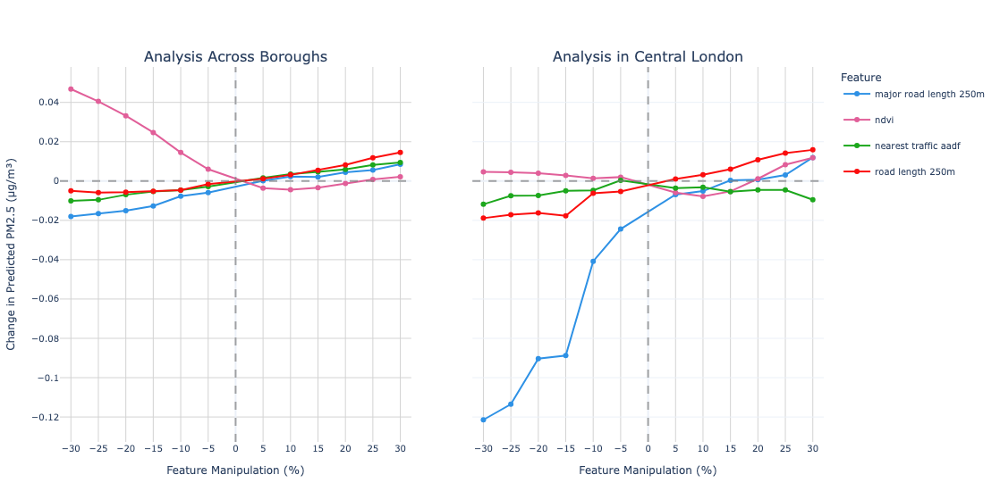

In [64]:
# Normalize feature names in both datasets
borough_summary["Feature"] = borough_summary["Feature"].str.strip()
central_summary["Feature"] = central_summary["Feature"].str.strip()

# Create one shared color mapping
features = sorted(
    set(borough_summary["Feature"]) |
    set(central_summary["Feature"])
)

palette = px.colors.qualitative.Dark24

feature_colors = {
    feature: palette[i % len(palette)]
    for i, feature in enumerate(features)
}

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        "Analysis Across Boroughs",
        "Analysis in Central London"
    ],
    shared_yaxes=True,
    horizontal_spacing=0.08
)

datasets = [
    (borough_summary, 1),
    (central_summary, 2)
]

for data, col in datasets:
    for feature in features:

        subset = data[data["Feature"] == feature].sort_values(
            "signed_pct"
        )

        if subset.empty:
            continue

        color = feature_colors[feature]

        fig.add_trace(
            go.Scatter(
                x=subset["signed_pct"],
                y=subset["change"],
                mode="lines+markers",
                name=feature.replace("_", " "),
                legendgroup=feature,
                showlegend=(col == 1),
                line=dict(color=color, width=2),
                marker=dict(color=color, size=6),
                customdata=subset[["change_%", "baseline"]],
                hovertemplate=(
                    "<b>%{fullData.name}</b><br>"
                    "Manipulation: %{x:+.0f}%<br>"
                    "Change: %{y:+.4f} µg/m³<br>"
                    "Percentage change: %{customdata[0]:+.4f}%<br>"
                    "Baseline: %{customdata[1]:.4f} µg/m³"
                    "<extra></extra>"
                )
            ),
            row=1,
            col=col
        )

    fig.add_hline(
        y=0,
        line_dash="dash",
        line_color="gray",
        opacity=0.7,
        row=1,
        col=col
    )

    fig.add_vline(
        x=0,
        line_dash="dash",
        line_color="gray",
        opacity=0.7,
        row=1,
        col=col
    )

fig.update_layout(
    width=1100,
    height=550,
    template="plotly_white",
    hovermode="closest",
    legend_title_text="Feature",
    font=dict(size=10),
    margin=dict(l=55, r=20, t=75, b=55)
)

fig.update_xaxes(
    title_text="Feature Manipulation (%)",
    range=[-32, 32],
    tickmode="array",
    tickvals=[-30, -25, -20, -15, -10, -5, 0, 5, 10, 15, 20, 25, 30],
    ticksuffix="%",
    showgrid=True,
    gridcolor="lightgray"
)

fig.update_yaxes(
    title_text="Change in Predicted PM2.5 (µg/m³)",
    showgrid=True,
    gridcolor="lightgray",
    col=1
)

fig.show()

fig.write_html(
    os.path.join(OUTPUT_DIR, "dose_response_comparison.html")
)

Surrogate R² vs real model: 0.9932
SHAP done in 7s


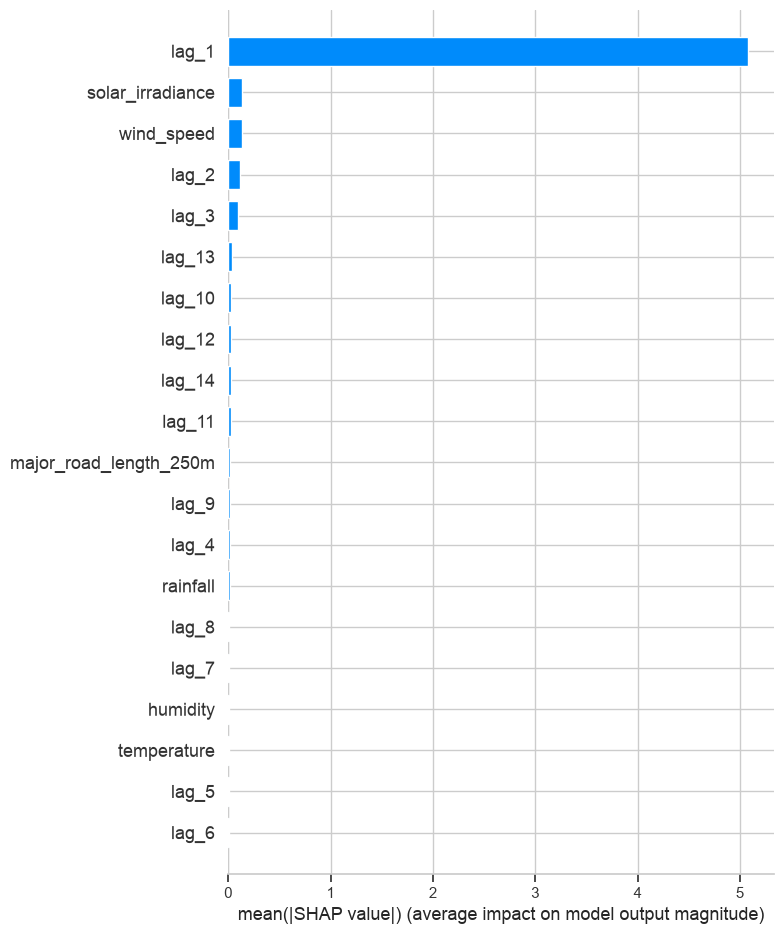

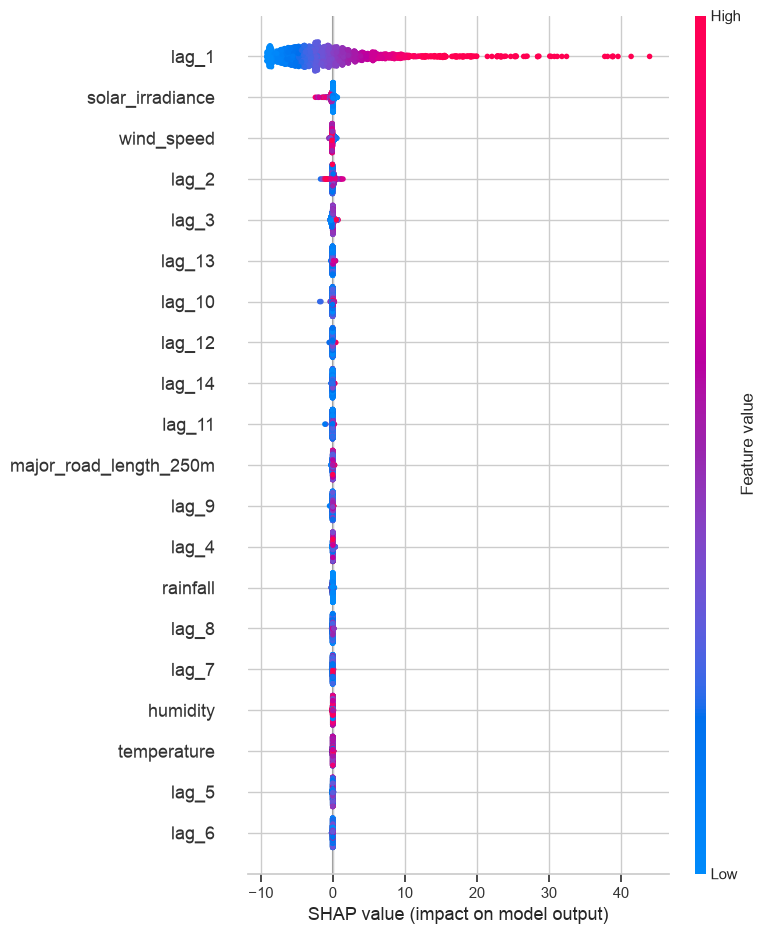

In [70]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Fit the surrogate on the model's own predictions (so it explains that model)
sub = X_train.sample(n=min(200_000, len(X_train)), random_state=RANDOM_STATE)
surrogate = RandomForestRegressor(n_estimators=60, max_depth=12, min_samples_leaf=50,
                                  random_state=RANDOM_STATE, n_jobs=-1)
surrogate.fit(sub, model.predict(sub))

# Fidelity check: how closely does it match the real model on test rows?
chk = X_test.sample(n=5000, random_state=RANDOM_STATE)
print("Surrogate R² vs real model:", round(r2_score(model.predict(chk), surrogate.predict(chk)), 4))

X_shap = X_test.sample(n=2000, random_state=RANDOM_STATE)
t0 = time.time()
shap_values = shap.TreeExplainer(surrogate).shap_values(X_shap, check_additivity=False)
print(f"SHAP done in {time.time()-t0:.0f}s")
np.save(os.path.join(OUTPUT_DIR, "shap_values_surrogate_L14.npy"), shap_values)

shap.summary_plot(shap_values, X_shap, max_display=20, plot_type="bar", show=False)
plt.tight_layout(); plt.show()
shap.summary_plot(shap_values, X_shap, max_display=20, show=False)
plt.tight_layout(); plt.show()

In [74]:
import numpy as np
import pandas as pd

# Settings
RANK_BY = "pm25_change_ugm3"     # or "pm25_change_%" to rank by relative change
FEATURES = ["ndvi", "nearest_traffic_aadf", "road_length_250m", "major_road_length_250m"]
                                 # set to None to include the land cover levers too
INCLUDE_CL = True                # False = rank boroughs only (Central London overlaps them)
MIN_LOCATIONS = 1                # e.g. 3 to ignore regions with very few test sites
TOP_K = 13

cand = cf_table.copy()
if FEATURES is not None:
    cand = cand[cand["feature"].isin(FEATURES)]
if not INCLUDE_CL:
    cand = cand[cand["region"] != "Central London"]
cand = cand[cand["n_locations"] >= MIN_LOCATIONS]

cand = cand.assign(abs_rank=cand[RANK_BY].abs())
top = cand.sort_values("abs_rank", ascending=False).head(TOP_K).copy()

# Plain-language reading of each row
def interpret(r):
    pm_up = r["pm25_change_ugm3"] > 0
    f_down = r["direction"] == "decrease"
    if r["feature"] == "ndvi":
        if f_down and pm_up:
            return "Less greenery -> PM2.5 increased (consistent with greenery mitigating pollution)"
        if (not f_down) and (not pm_up):
            return "More greenery -> PM2.5 decreased (consistent with greenery mitigating pollution)"
        if f_down and not pm_up:
            return "Less greenery -> PM2.5 decreased (counter-intuitive)"
        return "More greenery -> PM2.5 increased (counter-intuitive)"
    # traffic and road levers: more of the lever is expected to mean more PM2.5
    expected = (not f_down) == pm_up
    word = "decreased" if f_down else "increased"
    return (f"{r['feature']} {word} -> PM2.5 {'increased' if pm_up else 'decreased'} "
            f"({'as expected' if expected else 'counter-intuitive'})")

top["PM2.5 effect"] = np.where(top["pm25_change_ugm3"] > 0, "increased", "decreased")
top["interpretation"] = top.apply(interpret, axis=1)

out = (top.rename(columns={"feature_change_%": "feature change (%)",
                           "pm25_change_ugm3": "PM2.5 change (µg/m³)",
                           "pm25_change_%": "PM2.5 change (%)"})
          [["region", "n_locations", "feature", "feature change (%)", "baseline_pm25",
            "PM2.5 change (µg/m³)", "PM2.5 change (%)", "PM2.5 effect", "interpretation"]]
          .reset_index(drop=True))
out.index = out.index + 1
out.to_csv(os.path.join(OUTPUT_DIR, "top10_counterfactual_changes.csv"), index_label="rank")
display(out.round({"baseline_pm25": 2, "PM2.5 change (µg/m³)": 4, "PM2.5 change (%)": 3}))

# Optional: share of NDVI scenarios where less greenery raised PM2.5, by region
nd = cf_table[(cf_table["feature"] == "ndvi") & (cf_table["direction"] == "decrease")]
print("\nNDVI decreases that raised PM2.5:",
      f"{(nd['pm25_change_ugm3'] > 0).mean():.0%} of region x scenario cases",
      f"({nd.loc[nd['pm25_change_ugm3'] > 0, 'region'].nunique()} of {nd['region'].nunique()} regions)")

,region,n_locations,feature,feature change (%),baseline_pm25,PM2.5 change (µg/m³),PM2.5 change (%),PM2.5 effect,interpretation
1,Kensington & Chelsea,1,ndvi,-30,8.84,0.1443,1.632,increased,Less greenery -> PM2.5 increased (consistent w...
2,Kensington & Chelsea,1,ndvi,-25,8.84,0.1271,1.438,increased,Less greenery -> PM2.5 increased (consistent w...
3,Central London,3,major_road_length_250m,-30,11.57,-0.1214,-1.050,decreased,major_road_length_250m decreased -> PM2.5 decr...
4,Central London,3,major_road_length_250m,-25,11.57,-0.1135,-0.981,decreased,major_road_length_250m decreased -> PM2.5 decr...
5,Wandsworth,5,ndvi,-30,10.33,0.0986,0.955,increased,Less greenery -> PM2.5 increased (consistent w...
6,Kensington & Chelsea,1,ndvi,-20,8.84,0.0970,1.097,increased,Less greenery -> PM2.5 increased (consistent w...
7,Wandsworth,5,ndvi,-25,10.33,0.0959,0.928,increased,Less greenery -> PM2.5 increased (consistent w...
8,Merton,4,ndvi,-30,9.62,0.0913,0.949,increased,Less greenery -> PM2.5 increased (consistent w...
9,Central London,3,major_road_length_250m,-20,11.57,-0.0903,-0.781,decreased,major_road_length_250m decreased -> PM2.5 decr...
10,Central London,3,major_road_length_250m,-15,11.57,-0.0888,-0.768,decreased,major_road_length_250m decreased -> PM2.5 decr...



NDVI decreases that raised PM2.5: 63% of region x scenario cases (14 of 19 regions)


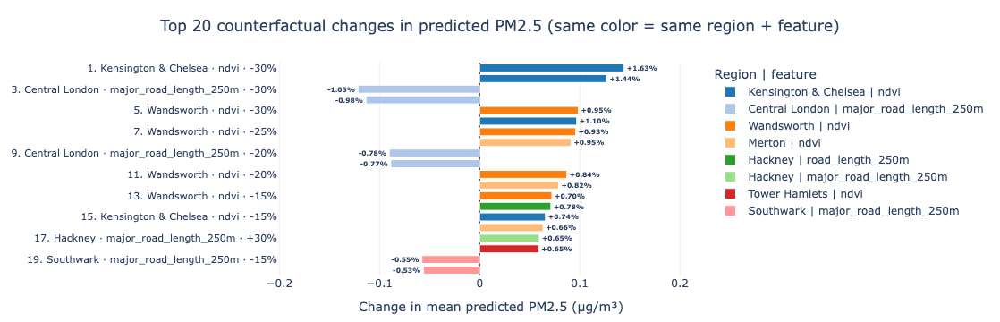

In [80]:
import os
import numpy as np
import plotly.graph_objects as go

df = out.reset_index().rename(columns={"index": "rank"})

df["label"] = [f"{r['rank']}. {r['region']} · {r['feature']} · {r['feature change (%)']:+d}%"
               for _, r in df.iterrows()]

# Exact percent change shown next to each bar (percent only, so it stays short)
df["text"] = [f"<b>{p:+.2f}%</b>" for p in df["PM2.5 change (%)"]]

fig = go.Figure()
for g in groups:
    d = df[df["group"] == g]
    fig.add_trace(go.Bar(
        y=d["label"], x=d["PM2.5 change (µg/m³)"], orientation="h",
        name=g, marker=dict(color=group_color[g], line=dict(color="white", width=1)),
        text=d["text"], textposition="outside", cliponaxis=False,
        textfont=dict(size=12),
        customdata=np.stack([d["PM2.5 change (%)"], d["baseline_pm25"],
                             d["n_locations"], d["interpretation"]], axis=-1),
        hovertemplate=("<b>%{y}</b><br>PM2.5 change: %{x:+.4f} µg/m³ (%{customdata[0]:+.3f}%)"
                       "<br>baseline: %{customdata[1]:.2f} µg/m³"
                       "<br>test locations: %{customdata[2]}"
                       "<br>%{customdata[3]}<extra></extra>")))

# Padding so outside labels stay inside the plot area, away from the y-axis names
lo, hi = df["PM2.5 change (µg/m³)"].min(), df["PM2.5 change (µg/m³)"].max()
span = max(hi, 0) - min(lo, 0)
pad = 0.30 * span
xr = [min(lo, 0) - (pad if lo < 0 else 0), max(hi, 0) + (pad if hi > 0 else 0)]

fig.update_layout(
    title=dict(text=f"Top {len(df)} counterfactual changes in predicted PM2.5 "
                    "(same color = same region + feature)", x=0.5, xanchor="center"),
    barmode="overlay", bargap=0.25,
    xaxis=dict(title="Change in mean predicted PM2.5 (µg/m³)", range=xr,
               zeroline=True, zerolinecolor="#444", zerolinewidth=1.5,
               gridcolor="rgba(0,0,0,0.08)"),
    yaxis=dict(autorange="reversed", categoryorder="array", categoryarray=df["label"],
               tickfont=dict(size=11), ticklabelstandoff=12,   # gap between names and plot
               automargin=True),
    legend=dict(title="Region | feature", orientation="v", x=1.02, y=1),
    plot_bgcolor="white", paper_bgcolor="white",
    height=max(520, 32 * len(df) + 160), margin=dict(l=20, r=20, t=70, b=50),
)

fig.write_html(os.path.join(MAPS_DIR, "top20_counterfactual_changes_plotly.html"))
fig.show()